# DX703 Final Project — Final Code Notebook (Part A)

**Due Date:** Sunday, December 6, 2026 at 11:59 p.m. (2-hour, 1-minute grace period)

**No late submissions!**

**Submit:** This completed `.ipynb` notebook and the separate technical report (Part B, `.pdf`).  

## Purpose

Build on your work from the **DX703 Final Project Milestone: Data Exploration and Baseline Modeling**. Using your previously selected dataset and established train/validation/test split, you will:

- Develop and evaluate a custom neural network, including experiments to improve its performance.
- Implement a pretrained model and investigate transfer-learning strategies.
- Compare both approaches with your milestone baseline using validation results.
- Select and finalize the best model based on predictive performance and computational constraints.
- Evaluate the selected model on the held-out test set and analyze its errors.

This assignment supports **both Food-101 (image classification) and HuffPost News Category (text classification)**. Use architectures and preprocessing appropriate to your dataset while addressing the same multiclass-classification objectives.

## Grading Overview

| Problem | Focus | Points |
|---|---|---:|
| 1 | Setup, preprocessing, and baseline recap | **10** |
| 2 | Custom neural network and experiments | **35** |
| 3 | Pretrained model and transfer learning | **35** |
| 4 | Comparison, selection, and final training | **30** |
| 5 | Final test evaluation and error analysis | **25** |
| **Total** | | **135** |

## Important Submission Requirements

- **Preserve the notebook structure.** Complete the provided code and Markdown cells without deleting or replacing them. You may add additional cells as needed. Keep all required results and written responses in their designated locations to support reliable grading without rerunning expensive experiments.

- **Submit a notebook with executed results.** Include the relevant outputs, training histories, comparison tables, metrics, and plots. Code alone is not sufficient evidence for full credit if its required results are missing.

- **Complete the written responses.** Answer questions in the designated Markdown cells, replacing the *Your Answer* placeholders. Provide concise but substantive explanations supported by your experimental results. More extensive discussion belongs in the technical report.

- **Document your experiments.** Use organized, reproducible code, consistent random seeds where practical, and clearly identified model configurations. Avoid hard-coded local paths or dependencies on inaccessible private files.

- **Manage computational constraints responsibly.** You may use documented, reproducible subsets when full-dataset experiments are impractical. Preserve the original train/validation/test separation, explain how subsets were selected, and make model comparisons on consistent or explicitly comparable validation data. Do not present subset results as full-dataset results.

- **Protect the held-out test set.** Use validation results exclusively for model development, tuning, and selection. The final model and evaluation protocol must be fixed in Problem 4 before examining test results in Problem 5. Do not revise the model based on test performance.

- **Preserve expensive experimental results.** You are not required to rerun computationally expensive training during grading. Save the relevant outputs, training configurations, and checkpoints when practical. Your notebook should document how the results were obtained and how the final evaluation could be reproduced.

- **Coordinate with the technical report.** The notebook should demonstrate your implementation, experimental evidence, and concise interpretations. The separate technical report (Part B) will present a more complete discussion of methodology, results, limitations, and conclusions.

## Problem 0 — Dataset Selection (0 pts)

Identify the dataset used for your final project. It must be the same dataset you used in the milestone.

**Selected dataset:** Food-101

*Delete the dataset you are not using.*

## Problem 1 — Setup, Preprocessing, and Baseline Recap (10 pts)

Reuse the dataset, split, and baseline developed in your milestone. You may improve your preprocessing pipeline, but document changes and retain a fair validation comparison. **Do not repeat all the milestone EDA or write another lengthy dataset description.**

- **A. Reusable data pipeline (4 pts)**
- **B. Baseline evidence (4 pts)**
- **C. Milestone-to-final transition (2 pts)**

### Part A — Reusable Data Pipeline (4 pts)

**Implementation (3 pts):**

- Set random seeds;
- import required packages;
- load the chosen dataset or saved splits;
- reuse exactly the established train/validation/test partition;
- implement the final preprocessing/data-loading functions or pipelines needed for modeling.
- Fit learned preprocessing only on training data, and apply training-only augmentation only to training examples.
- **Category consolidation (optional):** You may combine closely related target categories when justified by their meaning (e.g., *Arts* and *Arts and Leisure* in HuffPost). If you consolidated categories in the milestone, preserve that mapping. If you decide to consolidate categories now, apply the mapping consistently across all three splits without changing which observations belong to each split. **Category consolidation is not required.**
- Show split sizes and relevant shape/type sanity checks. **Do not evaluate on the test set.**

**Explanation (1 pt):** Summarize any preprocessing changes relative to the milestone and why they were made. If you consolidated target categories, explain which categories were combined and why. If you changed the category definitions since the milestone, explain how this affects comparisons with your original baseline; models using different category definitions are not directly comparable. If there are no changes, say so.

In [1]:
# P1.A — Load your established splits and construct/reuse preprocessing.
# Add imports, reproducibility settings, dataset-loading code, and pipeline code here.
# You may insert further code cells after this one.

# ============================================
# Useful Imports
# ============================================

# --- Standard Libraries
import time
import os
import math
import random
from collections import Counter
import warnings
import shutil
from pathlib import Path

# Suppress Warnings
warnings.filterwarnings('ignore', category=UserWarning, module='PIL.TiffImagePlugin')
os.environ["PYTHONWARNINGS"] = "ignore"

# suppress tensorflow metal plugin log messages: 
# Used Gemini: https://share.gemini.google/qAzBBESECeoc
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# --- Core Data / Numerics
import numpy as np
import pandas as pd

# --- Visualization
import matplotlib.pyplot as plt
import seaborn as sns              # optional
import matplotlib.ticker as mticker  # optional (for formatted axes)

# --- Progress Tracking
from tqdm import tqdm                # optional (nice for loops)

from IPython.display import display

# --- TensorFlow / Keras (Deep Learning)
import tensorflow as tf
from tensorflow.keras import layers, models, Input, callbacks, regularizers, initializers
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay, ExponentialDecay
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.layers import (
    Dense, Dropout, Flatten, MaxPooling2D, Conv2D,
    SeparableConv2D, GlobalAveragePooling2D, GlobalMaxPooling2D, BatchNormalization
)

# --- (Optional) Classical ML Baseline Tools
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# --- Hugging Face Datasets
from datasets import load_dataset, load_from_disk, DatasetDict
from datasets.features import ClassLabel

# --- Image Tools
from PIL import Image as PILImage
from PIL import Image, ImageStat, ImageOps
from datasets import Image as HFImage
import io



# ============================================
# Global Configuration & Small Utilities
# ============================================

# Reproducibility
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

# change image size if needed
IMAGE_SIZE = (512, 512)

# =============================
# IMAGES TO DROP, CROP, RELABEL
# =============================

# image index with associated coordinates for crop box
crop_imgs = {
    50524: (160, 0, 380, 260),       # image collage cropped to just the pho
    50612: (300, 240, 512, 512),     # cropping image of pho just to the bowl of pho rather than the whole thing since theres also a sandwich
    33410: (60, 220, 180, 512),      # cropping image to strawberry shortcake and leaving out the cup cakes to not confuse the model between the two labels 
    74241: (0, 310, 470, 512),       # cropping grilled salmon dish to just the salmon since french fries may confuse the model because it is also a label.
    74210: (80, 200, 420, 320),      # wok of salmon with chef and somewhat busy background. cropping into just the food.
    17799: (120, 260, 220, 350),     # cropping image of woman holding container with hot dog to keep main focus of pixels on hot dog and not other details like people or background details.
    17995: (160, 250, 420, 400),     # cropping image of hot dog at baseball game to get rid of background arena details
    17907: (160, 160, 340, 300),     # cropping to just the hot dog since it is a far away top down view of the table
    17986: (140, 300, 400, 400),     # cropping hot dog on elephant stuffed animal's lap so the focus is just on the hot dog.
    17494: (100, 300, 420, 420),     # cropping image of hot dog at baseball game to get rid of background arena details
    17750: (120, 280, 360, 512),     # cropping image of hot dog at baseball game to get rid of background arena details
    17442: (240, 420, 320, 490),     # cropping image of a woman by a table holding a hot dog to just the hot dogs on the table
    17987: (120, 160, 240, 280),     # cropping image around just the hot dog in the person's hands because the rest of the image is empty space/inside of the car
    71579: (100, 320, 380, 512),     # cropping churros to remove background details of people and the stand
    71564: (260, 240, 380, 380),     # cropping out instagram UI to focus just on churros
    71867: (200, 320, 500, 480),     # cropping out restaurant background to focus on churros
    32368: (100, 190, 400, 340),     # cropping out smartphone UI to focus on crabcake sandwich
    58642: (20, 240, 220, 400),      # cropping out person so just the curry is shown without any side dishes as well
    95957: (280, 100, 480, 420),     # cropping out side dish for filet mignon
    60111: (40, 100, 260, 220),      # cropping out side dishes for filet mignon
    32017: (180, 180, 320, 400),     # cropping out background to focus just on breakfast sandwich
    32204: (100, 240, 420, 500),     # cropping out city background to focus on breakfast sandwich
    31566: (40, 200, 280, 300),      # cropping out chef and kitchen to focus on breakfast sandwich
    39531: (260, 260, 512, 512),     # samosa but cropping out collage of menu/food truck to focus on samosa
    39720: (260, 280, 460, 380),     # samosa but cropping to just the dishes with samosas instead of the whole image with the server and background
    9505: (20, 400, 300, 512),       # guacamole but cropped to just the guacamole the man is making
    9074: (180, 380, 400, 512),      # guacamole but cropped to just the guacamole the man is making
    9198: (180, 0, 460, 240),        # guacamole but cropped to just the bowl of guacamole since it is on the far end of the table
    9120: (260, 280, 512, 512),      # guacamole but cropped to bottom left image in the collage since its the guacamole part of the collage
    9097: (300, 280, 420, 280),      # guacamole but cropping onto bowl of guacamole since there's a lot in the background and on the table
    9113: (340, 200, 500, 360),      # guacamole but cropped to guacamole bowl and remove the bag of chips that takes up more of the image
    70123: (200, 300, 390, 440),     # poutine but cropped to just the poutine and getting rid of graphic design in background
    70274: (200, 380, 400, 512),     # poutine but cropped around food to remove the person
    75290: (260, 260, 500, 500),     # collage of images and cropped down to spaghetti bolognese
    75256: (140, 0, 340, 100),       # crop to the spaghetti bolognese on the far end of table
    22945: (240, 100, 480, 300),     # cropped on the chocolate mousse and remove signs/background items
    26536: (200, 200, 400, 420),     # cropped out baseball game to focus on just ice cream bowl
    26450: (160, 60, 400, 260),      # cropped out background to focus on ice cream cup
    53520: (0, 60, 512, 275),        # cropped out label from container of edamame so the focus is on the food
    53269: (100, 320, 300, 512),     # cropped out other dishes to focus on edamame
    53894: (310, 120, 512, 512),     # cropped out soda can to focus on edamame
    53598: (110, 110, 220, 200),     # cropped to focus on bowl of edamame in the back of the table
    52710: (160, 220, 320, 340),     # cropped out other food in fridge to focus on lobster roll sandwiches
    53120: (180, 140, 420, 360),     # cropped out lobster roll sandwich since it barely shows from the wrapper. Will switch to onion rings label
    52722: (240, 140, 512, 420),     # cropped out chips bag to focus on lobster roll sandwich
    2051: (0, 220, 512, 512),        # cropped out woman to focus just on ramen
    1810: (120, 80, 512, 280),       # crop out most of the advertisement sign to focus on the ramen
    13009: (140, 280, 400, 420),     # cropped out side dishes to focus on fried rice
    12887: (300, 160, 500, 320),     # collage of photos, cropped to fried rice image
    8053: (230, 280, 360, 410),      # cropped to pizza and crop out baby/background
    8079: (60, 260, 440, 420),       # cropped to pizza on the stands
    620: (160, 120, 300, 260),       # beignet but cropped to just the food and leave out person/background
    44982: (60, 300, 360, 512),      # lobster bisque but cropped to just the food and leave out the person/background
    46938: (160, 280, 360, 440),     # cropping to french onion soup and remove person/background
    57197: (260, 20, 490, 240),      # collage of nachos but cropping to just one image of nachos
    57706: (20, 20, 490, 260),       # ad for nachos but cropping to just upper nachos image
    61278: (0, 320, 512, 512),       # caprese salad but cropping out background that takes up most of the image.
    60773: (0, 280, 460, 512),       # caprese salad but cropping out background hills and pool to focus on food
    2626: (140, 260, 280, 380),      # hamburger but cropping out background/mountains that take up a lot of space
    2659: (0, 260, 512, 512),        # hamburger but cropping out upper half of collage that shows a building
    4893: (60, 320, 440, 512),       # pork chop but cropping out woman to focus just on food
    66761: (0, 320, 300, 512),       # spaghetti carbonara but cropping out background to focus on food on bottom left corner
    66849: (260, 20, 480, 250),      # cropping 4 image collage to just the spaghetti carbonara
    59958: (0, 260, 340, 440),       # omelette but cropping out energy drink
    20040: (60, 200, 450, 450),      # fish and chips collage but cropping to main image of fried fish on top of fries
    19804: (60, 280, 512, 512),      # fish and chips but cropping out girl
    10849: (0, 300, 140, 512),       # miso soup but cropping out child to focus on bowl of soup
    865: (0, 380, 512, 512),         # prime ribs but cropping out background since it takes up most of the image
    1247: (70, 320, 440, 512),       # prime ribs but cropping out orange item in background that takes up most of the image
    770: (0, 340, 512, 512),         # prime ribs but cropping out person that takes up more than half the image
    18093: (0, 0, 512, 200),         # steak but cropping out bottom half of wine bottles
    18665: (120, 100, 390, 370),     # steak but cropping out instagram UI
    14852: (140, 320, 320, 512),     # hummus but cropping out people/background to focus on hummus dish
    40728: (140, 220, 380, 460),     # french fries but cropping out tree that takes up most of the image
    41071: (220, 320, 420, 460),     # french fries but cropping out blurry people on sides
    6342: (60, 240, 320, 512),       # sashimi but cropping out person that takes up most of the image
    5367: (330, 0, 512, 512),        # greek salad but cropping out sign
    5772: (30, 30, 480, 480),        # greek salad but cropping out frame
    20878: (0, 280, 240, 380),       # caesar salad but cropped out server/background details
    20863: (260, 320, 512, 512),     # caesar salad but crop out labeling that takes up half of image
    65990: (340, 20, 490, 240),      # baby back ribs but crop out other collage images
    65514: (140, 220, 420, 480),     # baby back ribs but crop out graphic design/packaging
    28829: (120, 380, 380, 460),     # foie gras but cropping out chef/background details
    56633: (240, 160, 480, 360),     # peking duck but cropping to dish of dumplings to relabel it since duck dish is ambiguous
    56949: (60, 200, 240, 440),      # peking duck but cropping to dish to remove background that takes up more space
    28206: (160, 340, 280, 480),     # tacos but cropping out child
    34613: (100, 380, 340, 512),     # mussels but cropping out woman
    34653: (180, 140, 340, 260),     # mussels but cropping out menu
    34877: (180, 180, 400, 330),     # mussels but cropping out sign
    96260: (260, 280, 480, 480),     # macarons but cropping out background items
    61952: (80, 50, 240, 490),       # macarons but cropping out other two collage images to focus on one
    61622: (0, 400, 512, 512),       # macarons but cropping out half of plastic container
    61667: (100, 80, 240, 512),      # macarons but cropping out to focus just one food and not signs
    61865: (180, 0, 500, 140),       # macarons but cropping out black and white graphic design that covers most of the image
    41966: (0, 380, 360, 512),       # chicken quesadilla but cropping out background that takes up most of the image
    41283: (0, 200, 300, 380),       # chicken quesadilla but focus on food
    41911: (10, 260, 490, 490),      # chicken quesadilla but cropped out top image in collage
    41869: (0, 260, 512, 470),       # chicken quesadilla but cropped out bag/table to focus on food
    37310: (0, 300, 512, 512),       # falafel but cropping out background details that cover half the image
    37220: (260, 0, 512, 512),       # falafel but cropping out left image in 2 image collage
    54136: (100, 240, 220, 400),     # pulled pork sandwich but cropping out person/background
    54273: (60, 300, 300, 512),      # pulled pork sandwich but crops out background
    24409: (20, 260, 260, 490),      # pad thai but crop out other food/drinks in collage
    52271: (0, 0, 512, 240),         # takoyaki but cropped on the pan
    51954: (60, 320, 340, 440),      # takoyaki but cropped to focus on food not the chefs
    52220: (0, 0, 512, 200),         # takoyaki but cropped to focus on it instead of octopus
    52084: (0, 140, 270, 440),       # takoyaki but focus on main group of them
    52066: (260, 60, 512, 440),      # takoyaki but crop out chef/grills
    52412: (180, 220, 320, 400),     # takoyaki but crop out person
    14149: (120, 280, 320, 512),     # panna cotta but crop out kitchen
    4169: (60, 160, 240, 340),       # chicken wings but cropping out waffles since waffles are also a label
    23639: (16, 300, 420, 480),      # lasagna but cropped out person/background to focus on plate
    23702: (40, 290, 320, 460),      # lasagna but cropped out window blinds/wine bottle
    11874: (200, 110, 512, 430),     # apple pie but crop out coffee and background details
    11486: (200, 200, 420, 380),     # apple pie but cropped out pie since plastic hides it. Recropped to burger to relabel as hamburger
    11512: (0, 200, 512, 512),       # apple pie but crop out background/sun glare
    30317: (0, 260, 512, 512),       # frozen yogurt but crop out restaurant photo in the 2 image collage
    30656: (0, 0, 280, 512),         # frozen yogurt but crop out dog on sidewalk
    73384: (0, 280, 300, 440),       # mac and cheese but crop out person/background
    73273: (120, 300, 420, 512),     # mac and cheese but cropping out background
    73134: (180, 280, 380, 440),     # mac and cheese but crop out person and most of the garlic bread
    46099: (260, 360, 500, 500),     # waffles but cropped to waffles from the 3 image collage
    31452: (80, 0, 440, 260),        # seaweed salad but cropping out labeling/plastic
    68269: (240, 0, 512, 512),       # bibimbap but cropping out food truck from photo collage
    68257: (20, 60, 240, 320),       # bibimbap but cropping out second dish in 2 photo collage
    68342: (60, 20, 320, 320),       # bibimbap but crop out white space/drinks
    3349: (20, 120, 512, 220),       # bruschetta but cropped to board of bruschetta in the back
    72153: (60, 310, 420, 460),      # cannoli but cropped out sparkler and person
    62743: (20, 270, 170, 400),      # croque madame but cropping out fries/background to not confuse model since fries is also a label
    62460: (100, 280, 300, 440),     # croque madame but cropping out drink/table 
    25443: (60, 280, 160, 512),      # cheesecake but focusing on plain cheesecake in left corner
    25109: (260, 180, 500, 500),     # cheesecake but 3 image collage of different desserts so its cropped around the cheesecake only
    66454: (40, 190, 380, 300),      # ravioli but it looks like mussels and some sort of sauce so cropping around mussels to relabel image as mussels
    35677: (280, 100, 420, 320),     # dumplings but cropping out kitchen equipment
    48440: (220, 0, 360, 180),       # clam chowder but cropping out person/background
    48581: (0, 120, 220, 220),       # clam chowder but cropping out sandwich/background
    79142: (220, 160, 512, 360),     # chocolate cake but cropping out tiramisu
    22074: (220, 310, 340, 370),     # pancakes but cropping out child and dishes of different types of food
    21932: (40, 140, 140, 250),      # pancakes but cropping out pancake maker machine/bowl/syrup
    81496: (100, 320, 280, 460),     # garlic bread but cropping out cat
    17166: (180, 120, 480, 300),     # garlic bread but cropping out stuffed animal/background
    17003: (100, 260, 360, 500),     # garlic bread but cropping out menu and container
    16963: (60, 100, 360, 300),      # garlic bread but cropping out person
    69006: (200, 180, 460, 460),     # cup cakes but cropping out sign/frame
    44152: (20, 100, 210, 400),      # french toast but cropping out chips/table
    74466: (280, 80, 420, 420),      # paella but cropping out chef/background
    43288: (140, 280, 380, 360),     # huevos rancheros but cropping out woman
    43441: (0, 190, 420, 512),       # huevos rancheros but cropping out beach background
    67514: (220, 220, 440, 380),     # sushi but cropping out other dishes
    8888: (60, 140, 460, 400),       # eggs benedict but cropping out frame
    3894: (80, 200, 440, 400),       # chicken wings but cropping on fries because it takes up more of the focus. relabeling to french_fries
    4171: (160, 180, 330, 320),      # chicken wings but 3 image collage so I cropped to the wings
    24746: (0, 170, 240, 340),       # pad thai but 2 image collage so I cropped to one of the pad thai images
    18115: (120, 80, 420, 220),      # steak but cropping around fries since they are more visible. relabeling to french_fries
}

# image indices to drop (non-relevant images, ambiguous food types, extremely poor quality images)
IMAGES_TO_DROP = [
    33022,  # strawberry_shortcake image that is some kind of fruit drink
    33638,  # strawberry_shortcake image that could be a strawberry shortcake but is very ambiguous and not clear
    33713,  # strawberry_shortcake image that could be a strawberry shortcake but is very ambiguous and not clear
    33317,  # strawberry_shortcake image but it is ambiguous since there are no visible strawberries and the cake is covered in almond slices
    33007,  # strawberry_shortcake image but it is ambiguous since it is a green cake with no visible strawberries
    33189,  # strawberry_shortcake image but it is a cup of ice cream or slushy with strawberry looking flavors
    33444,  # strawberry_shortcake image but there are cookies that are strawberry and cream flavor from the package in the background
    33182,  # strawberry_shortcake image but it is collage of different cakes which makes it more ambiguous. Also no strawberries visible.
    29672,  # grilled_cheese_sandwich image but it is unclear what they are. Massive pile of sandwiches with egg maybe?
    29486,  # grilled_cheese_sandwich image but it wrapped in paper so the model wouldn't know if it is a grilled cheese sandwich.
    29908,  # grilled_cheese_sandwich image but it is ambiguous since it could be a burger or a grilled cheese on a burger bun. Dropping rather than relabeling to hamburger.
    7190,   # risotto image but it is ambiguous. Dark food with no clear indication of what it is.
    6994,   # risotto image but dropping because main focus is on a man with a dog. There is a table of ingredients but it will confuse the model.
    6941,   # risotto image but it is ambiguous. Not sure what kind of food it is.
    37614,  # scallops image but it is a night outside resort location with no food.
    37711,  # scallops image but it is ambiguous because a chef is cooking food on a grill and the food is small compared to the majority of the image.
    50931,  # pho image but it is not food at all. purple background with designs.
    2414,   # hamburger image of outside a restaurant with a man holding a hamburger. Dropping because it is more ambiguous while the goal is to detect real food.
    15306,  # carrot_cake image but it is a lot of small servings with very dark lighting and people. Dropping because it might cause issues with model.
    26400,  # ice_cream image of cartons inside a fridge. Dropping because it is the container not the actual food.
    50380,  # pho image but dropping because of computer screen and mouse icon. Its more of an ambiguous image.
    92702,  # pho image but it looks like a kind of cake. Unsure what kind so I will drop it.
    50812,  # pho image but dropping because poor quality containers blur whats inside and it is a big difficult to tell what it is.
    50979,  # pho image but dropping because it is just a leaf on a plate.
    50652,  # pho image but it is actually an empty cup.
    50470,  # pho image but it is actually a bridge at sunset.
    50883,  # pho image but it is most likely tempura vegetables and other dishes.
    74120,  # grilled salmon image but it is a menu.
    73632,  # grilled salmon but ambiguous image since it is covered in sauce to the point you cant tell what it is.
    73699,  # grilled salmon salad but you can barely see the salmon.
    74137,  # grilled salmon but dropping because it doesnt look like salmon and is extremely blurry.
    73735,  # grilled salmon but dropping because it is too ambiguous with several dishes and a person. Not worth cropping.
    74046,  # grilled salmon but doesnt look like it. unsure what kind of food it is.
    17695,  # hot dog but it is actually Thomas the Tank Engine
    17905,  # hot dog but dropping because it is just a hot dog restaurant with no visible food
    17633,  # hot dog but dropping because it looks more like bread (baguette or some kind of long loaf)
    17556,  # hot dog but dropping because it looks like something fried, unsure what it is and poor quality image due to filters/text/etc.
    17786,  # hot dog but dropping because it looks like a food truck with no visible hot dogs
    17345,  # hot dog but dropping because it is a food stand with no visible hot dogs.
    17323,  # hot dog but dropping because it looks like a food truck with no visible hot dogs
    17481,  # hot dog buns but no hot dogs
    17864,  # hot dog but the image is ambiguous. it looks like there might be a hot dog in the wrap but cropping would be too small
    17723,  # hot dog but dropping because it is a corn dog
    17463,  # hot dog but dropping because it is a corn dog
    17453,  # hot dog but it is actually just a photo of a person
    71522,  # churros but it is actually a photo of a man
    71764,  # churros but it is a sign with no food
    71751,  # churros but it is ambiguous. Not ice cream but some kind of sweets
    71325,  # churros stand but churros is too small to crop on
    71996,  # churros but dropping because it is ambiguous. could be sprinkles/chocolate on churros or it could be a donut
    58999,  # chicken curry but dropping because it is just the packaging for butter chicken curry
    58991,  # chicken curry but dropping because it is a baby
    58673,  # chicken curry but dropping because it's two people
    58543,  # chicken curry but dropping because it is just a menu
    58947,  # chicken curry but dropping because it is just naan with a little bit of curry sauce on the bowl.
    58725,  # chicken curry but dropping because it is just people eating on a plane
    59229,  # chicken curry but dropping because it is looks like vegetables and rice
    58935,  # chicken curry but dropping because it is a table of food with low quality. Unsure what food there is.
    59174,  # chicken curry but dropping because it is ambiguous. Many dishes at a kitchen to serve
    60457,  # filet mignon but dropping because it is a group of people
    60706,  # filet mignon but dropping because it is a group of people
    60223,  # filet mignon but dropping because it is a bit ambiguous. definitely meat but low quality
    60334,  # filet mignon but dropping because it is a bit ambiguous. definitely meat but covered mostly in cheese
    95978,  # filet mignon but dropping because it doesnt look like it is filet mignon.
    60392,  # filet mignon but dropping because it is ambiguous. Wrapped in bacon and sauce, unsure what it is.
    32168,  # breakfast sandwich but dropping because it is just a drink and napkins
    31820,  # breakfast sandwich but dropping because it is some sort of microwave meal
    32024,  # breakfast sandwich but dropping because it is some sort of microwave meal
    31804,  # breakfast sandwich but dropping because it is just 3 drinks
    32167,  # breakfast sandwich but dropping because it is wrapped up and cant see the actual sandwich
    32117,  # breakfast sandwich but dropping because crop would require too small image and lose a lot of detail
    31567,  # breakfast sandwich but dropping because it is ambiguous. Ingredients are being made but its not all combined
    32090,  # breakfast sandwich but dropping because it is just a black square
    39167,  # samosa but dropping because it is a person
    39329,  # samosa but dropping because it is a food stand with no visible samosas big enough to crop to
    39566,  # samosa but dropping because I am not sure what food it is
    9529,   # guacamole but dropping because it is a person
    9079,   # guacamole but dropping because it is mainly graphics and the container
    9073,   # guacamole but dropping because it is the ingredients just not made yet
    9578,   # guacamole but dropping because it is too small to crop in on fresh made guacamole in the restaurant
    9155,   # guacamole but dropping because it is unclear if there is any guacamole at the table
    78871,  # guacamole but dropping because it is a bit ambiguous. There is some guacamole in a wrap and a side of chips. 
    9309,   # guacamole but dropping becauae it is an empty bowl
    9671,   # guacamole but dropping because it is just tortilla chips
    69781,  # poutine but dropping because it is a poutine food truck not the food
    75474,  # spaghetti bolognese but dropping because it is an office space, not food.
    100820, # spaghetti bolognese but dropping because it is ambiguous. It looks like only sauce in a container
    75024,  # spaghetti bolognese but dropping because it is clearly not the dish. Looks like a brown meat sauce.
    75547,  # spaghetti bolognese but dropping because it doesnt look like it. Gormet dish of a different pasta with some tomato cubes
    63849,  # gyoza but dropping because it is ambiguous what the chef is making
    97109,  # gyoza but dropping because it is unclear what it is. gormet kind of salad?
    23060,  # chocolate mousse but dropping because it is unclear based on lighting/quality. 
    22971,  # chocolate mousse but dropping because it might confuse model. edible gold leaf over most of the chocolate mousse
    23191,  # chocolate mousse but dropping because it is poor quality and hard to tell if it is cup cakes or mousse
    22531,  # chocolate mousse but dropping because it looks more like chocolate candy
    22838,  # chocolate mousse but dropping because it is the wrapper of chocolate mousse candy
    26346,  # ice cream but dropping because it is the flavor menu board
    26654,  # ice cream but dropping because they are cartons
    26493,  # ice cream but dropping because it is an ice cream stand with only cartons visible
    26321,  # ice cream but dropping because it is a carton
    26833,  # ice cream but dropping because it is a freezer with ice cream. no ice cream visible
    26384,  # ice cream but dropping because it only shows a chef
    26529,  # ice cream but dropping because it is the outside of an ice cream shop
    26656,  # ice cream but dropping because it is an ice cream stand with not enough to crop to
    26675,  # ice cream but dropping because they are cartons
    26345,  # ice cream but dropping because no ice cream visible, only gummy bears and cone
    26839,  # ice cream but dropping because it is an ice cream wrapper
    26820,  # ice cream but dropping because it is an ice cream wrapper
    53918,  # edamame but not able to crop enough of the actual food from the container
    53959,  # edamame but dropping because it looks like some kind of sandwich (no edamame)
    53060,  # lobster roll sandwich but dropping because it is just a food stand
    53237,  # lobster roll sandwich but dropping because it would take too small of a crop to focus on sandwich
    1502,   # ramen but dropping because it is only the ramen cups without showing the food
    2207,   # ramen but dropping because it is a painting of soup
    1958,   # ramen but dropping since you cant see ramen in bowl that the server is holding
    1713,   # ramen but dropping because it is packages of ramen instead of a clearer image of the meal
    2150,   # ramen but dropping because it is a package of ramen instead of a clearer image of the meal
    1952,   # ramen but dropping because it is a package of ramen
    1824,   # ramen but dropping because most of the image is an ad with too small of a crop to focus on ramen
    13444,  # fried rice but dropping because it is a package of sweet apple
    13203,  # fried rice but dropping because it is a man
    13062,  # fried rice but dropping because it is a man
    13079,  # fried rice but dropping because it is a chef
    13152,  # fried rice but dropping because it is vegetables on the grill, not fried rice.
    13395,  # fried rice but dropping because it is vegetables and meat on the grill, not fried rice.
    12780,  # fried rice but dropping because it is unclear what it is. Fried food but not fried rice
    7567,   # pizza but dropping because no pizza shown, only a pizza shop
    8121,   # pizza but dropping because it is a vietnam logo
    8110,   # pizza but dropping because its a pizza box
    8199,   # pizza but dropping because its a kitchen
    7907,   # pizza but dropping because it is a baby
    7915,   # pizza but dropping because its just a restaurant
    8002,   # pizza but dropping because its just restaurant graphic design
    7548,   # pizza but dropping because its just restaurant graphic design
    8195,   # pizza but dropping because its a group of people
    7722,   # pizza but dropping because most of the image are people. They're eating pizza but i think it would confuse the model if I included it
    7888,   # pizza but dropping because its an inside of brick oven 
    7886,   # pizza but its just drinks
    228,    # beignet but its people
    508,    # beignet but its people
    279,    # beignet but its people 
    98,     # beignet but its people
    171,    # beignet but its a sign
    381,    # beignet but its a sign
    165,    # beignet but its a chef and too small to crop on the food
    646,    # beignet but its some other kind of pastry
    355,    # beignet but its a chef
    747,    # beignet but not enough shows to justify cropping (mostly paper bag full of them and 1 small beignet on far left)
    55800,  # bread pudding but mostly container. not worth cropping
    56094,  # bread pudding but its batman
    55583,  # bread pudding but ambiguous because it has ice cream which is also another label
    55700,  # bread pudding but its actually a tomato based dish
    55911,  # bread pudding but its a menu
    44283,  # lobster bisque but its a container
    44401,  # lobster bisque but unsure what food it is. definitely not soup consistency
    44995,  # lobster bisque but its spaghetti and lobster
    44575,  # lobster bisque but its packaging
    44261,  # lobster bisque but its ambiguous. unsure so dropping to be safe
    44590,  # lobster bisque but its a lobster not the soup
    44304,  # lobster bisque but its a lobster not the soup
    44306,  # lobster bisque but its a lobster not the soup
    47013,  # french onion soup but it looks more like pastry
    46557,  # french onion soup but it looks like a different kind of soup
    47022,  # french onion soup but it looks like a different kind of soup
    46796,  # french onion soup but it looks more like pastry
    46861,  # french onion soup but it is ambiguous what type of soup it is
    46667,  # french onion soup but it is ambiguous what type of soup it is
    49980,  # shrimp and grits but its an office
    50151,  # shrimp and grits but its the outside of a restaurant
    49833,  # shrimp and grits but its a water scene
    51683,  # cheese plate but its just a plate no food
    51154,  # cheese plate but its just a plate no food
    57657,  # nachos but its just a child
    57093,  # nachos but its just a person
    60759,  # caprese salad but its just two chefs doing food prep
    2384,   # hamburger but dropping because its not food
    2948,   # hamburger but dropping because its not food
    2677,   # hamburger but dropping because its not food
    2781,   # hamburger but dropping because its not food
    2982,   # hamburger but dropping because its not food
    2573,   # hamburger but dropping because its not food
    2456,   # hamburger but dropping because burgers are completely wrapped
    2510,   # hamburger but its just wrappers and empty plate
    2654,   # hamburger but dropping because its not food
    2912,   # hamburger but its just an empty plate
    70787,  # ceviche but dropping because its ambiguous
    66803,  # spaghetti carbonara but its an egg. Ambiguous that it is deviled or benedict so dropping instead.
    67146,  # spaghetti carbonara but its a different pasta dish (tomato based)
    67324,  # spaghetti carbonara but its a different pasta dish (penne)
    67285,  # spaghetti carbonara but its a completely different dish
    66930,  # spaghetti carbonara but its empty plates
    67065,  # spaghetti carbonara but its a completely different dish
    59852,  # omelette but its a chef and a customer
    95632,  # omelette but its some sort of fried meat
    59637,  # omelette but its boiled eggs
    59863,  # omelette but its a mug
    59408,  # omelette but its a completely different dish
    59381,  # omelette but dropping because its being made by a chef and not finished yet
    15306,  # carrot cake but dropping because its hard to tell what the dishes are (several small servings)
    15340,  # carrot cake but its a restaurant
    15193,  # carrot cake but dropping due to it being wrapped in plastic and hard to crop properly
    20127,  # fish and chips but its a flower
    19842,  # fish and chips but its a drink
    34170,  # beef tartare but its a completely different dish
    33880,  # beef tartare but its an inside of a building
    34313,  # beef tartare but its a chef
    34191,  # beef tartare but its clams. Can't relabel since its not mussels
    33778,  # beef tartare but dropping because there's a bunch of small dishes with dark lighting. not worth cropping
    34128,  # beef tartare but unsure what food it is. covered in cheese
    16461,  # beet salad but its ambiguous. could be strips of beet and other vegetables but also looks like some fries. dropping to be safe
    16364,  # beet salad but its an empty plate
    81100,  # beet salad but ambiguous what kind of salad it is. drop to be safe
    16341,  # beet salad but completely different dish
    15911,  # beet salad but looks like squash or some kind of fruit
    10535,  # miso soup but no visible soup only containers
    10599,  # miso soup but no visible soup only containers
    11201,  # miso soup but no visible soup only containers
    1164,   # prime rib but collage of images and hard to tell if there are ribs in any of them
    1083,   # prime rib but horse logo
    1435,   # prime rib but outdoor seating
    955,    # prime rib but menu
    1181,   # prime rib but menu
    755,    # prime rib but its far in background not worth cropping
    1390,   # prime rib but its far in background not worth cropping
    40224,  # club sandwich but completely different dish
    40476,  # club sandwich but completely different dish
    40008,  # club sandwich but completely different dish
    18735,  # steak but aging meat on racks
    18166,  # steak but building
    18508,  # steak but 2 people
    18467,  # steak but restaurant seating
    63193,  # gnocchi but its people
    63494,  # gnocchi but its people
    63519,  # gnocchi but completely different dish (pasta/vegetables)
    63002,  # gnocchi but completely different dish
    96753,  # gnocchi but completely different dish
    63436,  # gnocchi but completely different dish
    63545,  # gnocchi but completely different dish
    63122,  # gnocchi but completely different dish
    63045,  # gnocchi but completely different dish
    14735,  # hummus but its hummus containers 
    14664,  # hummus but its hummus containers
    14976,  # hummus but its hummus containers
    14497,  # hummus but its a person
    14813,  # hummus but its people
    14264,  # hummus but its a building
    14912,  # hummus but its a different dish
    41052,  # french fries but its McDonalds logo
    40921,  # french fries but its a drink
    40825,  # french fries but its a different dish
    6747,   # sashimi but too much packaging. dropping to not confuse model
    6422,   # sashimi but its ambiguous. menu says sushi but image is zoomed in too much it could be sushi or sashimi
    5282,   # greek salad but its restaurant seating
    5807,   # greek salad but its wrapping
    5424,   # greek salad but its just greens and a lemon slice
    5533,   # greek salad but packing makes it hard to crop well. dropping to not confuse model
    5551,   # greek salad but packing makes it hard to crop well. dropping to not confuse model
    20652,  # caesar salad but doesnt seem like it is
    20556,  # caesar salad but its a person
    20968,  # caesar salad but its a person
    20956,  # caesar salad but its a different dish
    20392,  # caesar salad but its a different dish
    65321,  # baby back ribs but dropping because they are completely wrapped in tin foil
    65535,  # baby back ribs but just bones
    65710,  # baby back ribs but just bones
    28862,  # foie gras but ambiguous what it is
    28977,  # foie gras but ambiguous what it is
    28825,  # foie gras but dropping because its packaging. drop to be safe
    29000,  # foie gras but dropping because its packaging. drop to be safe
    28660,  # foie gras but on grill with large flame. dropping to not confuse model
    28675,  # foie gras but dropping because its packaging. drop to be safe
    28745,  # foie gras but dropping because its packaging. drop to be safe
    29188,  # foie gras but dropping because its packaging. drop to be safe
    28896,  # foie gras but dropping because it would require small crop to focus on it
    56527,  # peking duck but its a chef
    56724,  # peking duck but its a different dish
    56351,  # peking duck but its a different dish
    56840,  # peking duck but its a menu
    56945,  # peking duck but none visible
    56914,  # peking duck but window blinds
    56623,  # peking duck but packaging
    94744,  # peking duck but ambiguous dish
    27823,  # tacos but restaurant signs
    28481,  # tacos but restaurant signs
    27806,  # tacos but restaurant signs
    27842,  # tacos but restaurant signs
    28000,  # tacos but restaurant signs
    27799,  # tacos but swans
    28234,  # tacos but different dish
    28412,  # tacos but different dish
    34666,  # mussels but ambiguous dish
    34750,  # mussels but seafood stand
    87470,  # mussels but clams
    35107,  # mussels but menu
    62077,  # macarons but flowers
    62227,  # macarons but dropping because crop would be too small. actual macarons are quite small compared to the rest of the composition
    62181,  # macarons but ambiguous image
    41783,  # chicken quesadilla but blurry image with main focus on drink. not worth cropping
    41529,  # chicken quesadilla but ambiguous angle which makes it hard to tell what the food is
    41787,  # chicken quesadilla but its salad (not greek, caesar, or seafood so dropping)
    27465,  # red velvet cake but a lot of glare and too small to crop
    27380,  # red velvet cake but main cake is green while the red velvet cake is at the bottom. too difficult to crop
    37485,  # falafel collage but too blurry/ambiguous
    37214,  # falafel collage but too blurry/ambiguous
    36870,  # falafel collage with falafel building and other food
    19469,  # tiramisu but it looks more like cake
    54602,  # pulled pork sandwich but its a restaurant
    42675,  # escargots but ambiguous
    42142,  # escargots but its packaging
    42079,  # escargots but ambiguous
    24116,  # pad thai but not food
    24047,  # pad thai but not cooked yet (shows ingredients in outdoor kitchen)
    24407,  # pad thai but chef/kitchen
    24528,  # pad thai but chef/kitchen
    24417,  # pad thai but ambiguous
    24585,  # pad thai but ambiguous
    24272,  # pad thai but ambiguous
    24328,  # pad thai but ambiguous
    52311,  # takoyaki but card game
    51975,  # takoyaki but restaurant
    51774,  # takoyaki but restaurant
    52473,  # takoyaki but too difficult to crop
    52198,  # takoyaki but ambiguous
    51997,  # takoyaki but food stand rather than the food
    13664,  # panna cotta but its pudding
    4281,   # chicken wings but its CNN news logo
    4330,   # chicken wings but its a stuffed animal
    4108,   # chicken wings but its a group of people
    3904,   # chicken wings but in marinade bag rather than on plates/grills/etc.
    23754,  # lasagna but its broken glass and text
    23643,  # lasagna but collage of photos with food and people
    23367,  # lasagna but its people
    23472,  # lasagna but its woodchips at a playground
    23767,  # lasagna but its a restaurant
    23292,  # lasagna just packaging
    11437,  # apple pie but ambiguous sandwich looking food
    30290,  # frozen yogurt but restaurant
    30058,  # frozen yogurt but restaurant
    30423,  # frozen yogurt but restaurant
    30053,  # frozen yogurt but restaurant
    30259,  # frozen yogurt but restaurant
    30667,  # frozen yogurt but restaurant
    30741,  # frozen yogurt but cartons
    30142,  # frozen yogurt but candy ingredients rather than the frozen yogurt
    30181,  # frozen yogurt but candy ingredients rather than the frozen yogurt
    73341,  # mac and cheese but its a lion
    73065,  # mac and cheese but its fried mozzarella sticks
    46477,  # waffles but its people
    46214,  # waffles but its people
    46378,  # waffles but its people
    45805,  # waffles but its baked goods
    57774,  # donut but its a sign not the actual food
    58156,  # donut but its a sign not the actual food
    58224,  # donut but its a restaurant
    58009,  # donut but its a restaurant
    57927,  # donut but its a restaurant
    58301,  # donut but its shaped like a person and ambiguous. dropping to not confuse model on typical donuts
    68901,  # bibimbap but its a keyboard
    68384,  # bibimbap but its a keyboard
    68869,  # bibimbap but its a restaurant
    76825,  # bruschetta but its pretzel sticks
    3006,   # bruschetta but its a box
    3402,   # bruschetta but its boxes/books
    72217,  # cannoli but ambiguous what kind of dessert it is
    62822,  # croque madame but it looks like salad (plain, unable to relabel)
    62655,  # croque madame but its a different dish
    62656,  # croque madame but it looks like crepes with an egg
    24949,  # cheesecake but its a restaurant
    49370,  # beef carpaccio but it looks like salad with fish (not sure if its seaweed salad so dropping to be safe)
    49299,  # beef carpaccio but thicker pieces of meat in a cup
    92140,  # beef carpaccio but ambiguous 
    66565,  # ravioli but its a food truck
    66250,  # ravioli but its the packaging
    66289,  # ravioli but its people
    66724,  # ravioli but its ambiguous
    35911,  # dumplings but dropping because too many types of food with low quality image not worth cropping
    35899,  # dumplings but its a menu
    35446,  # dumplings but its ambiguous. maybe cupcakes but not sure so I am dropping it.
    48145,  # clam chowder but its fruit
    48678,  # clam chowder but its traffic
    10092,  # chocolate cake but dropping because its design makes it ambiguous (colored in fondant)
    21983,  # pancakes but not pancake batter so dropping to not confuse model
    22267,  # pancakes but ambiguous. maybe red velvet cake, something fried, etc.
    22259,  # pancakes but it looks like crepes
    22213,  # pancakes but its ambiguous
    22308,  # pancakes but its still batter so dropping to be safe
    16805,  # garlic bread but its mostly packaging
    16662,  # garlic bread but ambiguous
    69201,  # cup cakes but dropping because packaging covers most of it
    69475,  # cup cakes but dropping because packaging covers most of it
    44141,  # french toast but its a restaurant
    43638,  # french toast but its ambiguous (could be a salad with garlic bread, unsure)
    43606,  # french toast but its ambiguous (could be pancakes with fruits/syrup, unsure)
    74395,  # paella but its a chef (paella too small to justify cropping)
    74488,  # paella but its a restaurant
    74323,  # paella but ambiguous because its still liquidy and being cooked
    45496,  # onion rings but its a completely different food/wrapper
    38423,  # oysters but wrapped up in netting so dropping to not confuse model
    38542,  # oysters but ambiguous because its fried
    47492,  # spring rolls but its a salad (unsure what type so dropping)
    47779,  # spring rolls but its packaging
    47319,  # spring rolls but its different food entirely
    47613,  # spring rolls but its ambiguous
    43046,  # huevos rancheros but ambiguous. dont see any eggs
    43076,  # huevos rancheros but looks like different food
    43194,  # huevos rancheros but looks like different food
    67861,  # sushi but its a restaurant sign
    67565,  # sushi but its a restaurant sign
    68081,  # sushi but its a restaurant
    36686,  # creme brulee but its a restaurant
    36686,  # creme brulee but its a chef
    36657,  # creme brulee but its a chef
    78569,  # eggs benedict but its different food
    8516,   # eggs benedict but its different food
    61951,  # macarons but too blurry to tell
    17482,  # hot dog but different kind of sandwich
    17665,  # hot dog but different kind of sandwich
    4245,   # chicken wings but copy of image 3894
    46123,  # waffles but dropping because its mostly whipped cream which might confuse model to classify it as ice cream
    91235,  # waffles but dropping because its mostly whipped cream which might confuse model to classify it as ice cream
    22486,  # pancakes but ambiguous
    29883,  # grilled cheese sandwich but its a sub
    50878,  # pho but its ambiguous. could be ramen but dropping to be safe
    57379,  # nachos but looks like plain tortilla chips
]

# image indices with image label fixes - found mislabeled images from EDA notebook
IMAGES_TO_RELABEL = {
    33020: 'ice_cream',             # strawberry_shortcake but it is a refrigerator of ice cream flavors
    33112: 'pancakes',              # strawberry_shortcake but it is a plate of pancakes with strawberries
    33305: 'cup_cakes',             # strawberry_shortcake but it is 2 cupcakes and maybe one is strawberry shortcake flavor but the other is a chocolate flavor
    33295: 'chocolate_cake',        # strawberry_shortcake but it is a chocolate cake
    33179: 'cup_cakes',             # strawberry_shortcake because it is a strawberry shortcake flavored cupcake but it might be a bit misleading for the model so I'll consider it cup_cakes
    33021: 'cup_cakes',             # strawberry_shortcake because it is a strawberry shortcake flavored cupcake but it might be a bit misleading for the model so I'll consider it cup_cakes
    6888: 'mussels',                # risotto but its more ambiguous. The mussels stand out the most in the image so I'll relabel it.
    50496: 'spring_rolls',          # pho but the main food are likely spring rolls.
    50525: 'spring_rolls',          # pho but it is most likely Vietnamese fried spring rolls over rice noodles and vegetables.
    50826: 'beef_carpaccio',        # pho image but it is thin slices of raw meat. Most likely beef carpaccio since they are very thin slices of meat
    50362: 'beef_carpaccio',        # pho image but it is thin slices of raw meat. Most likely beef carpaccio since they are very thin slices of meat
    73841: 'onion_rings',           # grilled salmon but a large portion of the image are onion rings, so I will relabel it to that.
    9334: 'nachos',                 # guacamole but it is a lot of tortilla chips with guacamole, salsa, and cheese
    22931: 'chocolate_cake',        # chocolate mousse but it looks more like chocolate cake
    22520: 'chocolate_cake',        # chocolate mousse but it looks more like chocolate cake
    53507: 'fried_rice',            # edamame but it is actually fried rice
    53717: 'sashimi',               # edamame but it looks like raw seafood like sashimi
    52980: 'sushi',                 # lobster roll sandwich but it looks like sushi
    53120: 'onion_rings',           # lobster roll but barely shows so cropped image to onion rings and relabel.
    7921: 'french_fries',           # pizza but its actually a cup of french fries
    55869: 'chocolate_cake',        # bread pudding but it looks like chocolate cake or mousse. thicker than mousse though
    71069: 'tacos',                 # ceviche but its actually tacos
    33966: 'shrimp_and_grits',      # beef tartare but its actually shrimp and grits
    56633: 'dumplings',             # peking duck but ambiguous so cropped to dumplings. relabeled to dumplings
    27487: 'macarons',              # red velvet cake but its actually macarons
    19439: 'ice_cream',             # tiramisu but its actually tiramisu ice cream
    11486: 'hamburger',             # apple pie but hamburger is more visible so I cropped onto the burger instead
    58130: 'cup_cakes',             # donut but they are cupcakes
    68568: 'steak',                 # bibimbap but it looks like strips of steak
    72335: 'chocolate_cake',        # cannoli but it is a chocolate cake.
    72549: 'tiramisu',              # cannoli but its tiramisu
    66454: 'mussels',               # ravioli but its a plate with mussels. cropped to focus on the mussels
    22439: 'waffles',               # pancakes but its waffles
    16632: 'strawberry_shortcake',  # garlic bread but it looks like a strawberry shortcake flavored cake
    36249: 'chocolate_cake',        # creme brulee but its chocolate cake
    3894: 'french_fries',           # chicken wings but cropped around fries since it took up more of the image. relabeling to french fries
    18115: 'french_fries',          # steak but fries are more visible so I cropped on the fries and relabeled to french fries
}

# image indices of duplicate and near duplicates to drop. Near duplicates are the same images just with an effect applied (added blur, grain, text, etc.) - found through cleanvision Imagelab in EDA notebook
DUPLICATES_TO_DROP = [
    
    # EXACT DUPLICATES
    636,    # beignets
    1334,   # prime_rib
    17999,  # steak
    5680,   # greek_salad
    9791,   # chocolate_cake
    9817,   # chocolate_cake
    79522,  # fried_calamari
    13395,  # fried_rice
    80044,  # panna_cotta
    79965,  # panna_cotta
    14700,  # hummus
    80776,  # beet_salad
    17057,  # garlic_bread
    20744,  # caesar_salad
    82751,  # pancakes
    23235,  # lasagna
    23241,  # lasagna
    83102,  # lasagna
    83484,  # pad_thai
    28676,  # foie_gras
    31769,  # breakfast_burrito
    32020,  # breakfast_burrito
    86468,  # strawberry_shortcake
    35706,  # dumplings
    36849,  # falafel
    41704,  # chicken_quesadilla
    45282,  # onion_rings
    46935,  # french_onion_soup
    91021,  # french_onion_soup
    91353,  # clam_chowder
    91604,  # beef_carpaccio
    50626,  # pho
    50685,  # pho
    93179,  # edamame
    54743,  # deviled_eggs
    55045,  # deviled_eggs
    57054,  # nachos
    95775,  # caprese_salad
    95894,  # macarons
    63143,  # gnocchi
    65484,  # baby_back_ribs
    97079,  # baby_back_ribs
    65397,  # baby_back_ribs
    97585,  # spaghetti_carbonara
    97804,  # spaghetti_carbonara
    97791,  # spaghetti_carbonara
    69025,  # cup_cakes
    99228,  # churros
    99969,  # grilled_salmon
    73544,  # grilled_salmon
    100151, # paella
    79316,  # apple_pie
    86415,  # strawberry_shortcake
    86785,  # beef_tartare
    100427, # spaghetti_bolognese

    # NEAR DUPLICATES (DUPLICATES BUT VARIATION IN QUALITY - ADDED BLUR, GRAIN/NOISE, TEXT, ETC.)
    453,    # beignets
    757,    # prime_rib
    75622,  # prime_rib
    1366,   # prime_rib
    1391,   # prime_rib
    1364,   # prime_rib
    75636,  # prime_rib
    7976,   # pizza
    11662,  # apple_pie
    12612,  # fried_calamari
    79511,  # fried_calamari
    16070,  # beet_salad
    81199,  # hot_dog
    27358,  # red_velvet_cake
    28717,  # foie_gras
    32710,  # crab_cakes
    86384,  # strawberry_shortcake
    35206,  # dumplings
    37227,  # falafel
    89410,  # escargots
    42784,  # huevos_rancheros
    46668,  # french_onion_soup
    49700,  # shrimp_and_grits
    92398,  # cheese_plate
    52726,  # lobster_roll_sandwich
    52630,  # lobster_roll_sandwich
    92951,  # lobster_roll_sandwich
    53198,  # edamame
    54265,  # pulled_pork_sandwich
    93768,  # deviled_eggs
    57824,  # donuts
    59252,  # omelette
    95101,  # omelette
    63192,  # gnocchi
    97549,  # ravioli
    97458,  # ravioli
    97749,  # spaghetti_carbonara
    98881,  # ceviche
    98843,  # ceviche
    71861,  # cannoli
    72343,  # cannoli
    73721,  # grilled_salmon
    74261,  # paella
    100185  # paella
]

# final image to drop (found after verifying brightness in EDA notebook. must drop in this order for consistent index number)
dark_image_idx = [9021]

# ================
# HELPER FUNCTIONS
# ================

def format_hms(seconds: float) -> str:
    """Convert seconds to HH:MM:SS format."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

def normalize_image_size(image, image_size=IMAGE_SIZE):
    """
        Normalizes images to the specified image_size (pixels) while maintaining the original aspect ratio through padding remaining pixels black.
    """
    # handles already loaded PIL Image objects and file paths
    img = image if isinstance(image, Image.Image) else Image.open(image)

    # formats to RGB
    img = img.convert("RGB")

    # Return resized image (padded if scaled up)
    return ImageOps.pad(img, image_size, method=Image.Resampling.LANCZOS, color=(0,0,0))

def resize_batch(batch):
    """
        Processes images in batches for better performance.
    """
    batch['image'] = [normalize_image_size(img, IMAGE_SIZE) for img in batch['image']]
    return batch

def crop_and_normalize(img, idx):
    """
        Checks if image is flagged for cropping. Applies crop and normalizes size. Returned updated image. 
    """
    if idx in crop_imgs:
        crop_box = crop_imgs[idx]

        # crop image
        cropped_img = img['image'].crop(crop_box)

        # rescale to standardized size for model inputs
        resized_img = normalize_image_size(cropped_img, IMAGE_SIZE)

        # update image in the dataset row
        img['image'] = resized_img
    
    return img

def drop_image(dataset, indices):
    """
        Filters out images from dataset. Ensures the list of indices are unique.
    """
    drop_set = set(indices)

    filtered_data = dataset.filter(lambda img, idx: idx not in drop_set, with_indices=True)

    if len(drop_set) != len(indices):
        print(f"List of images contained duplicate indices. Dropping {len(drop_set):,} images.")
    else:
        print(f"Dropped {len(drop_set):,} images.")

    print(f"\nNew dataset size: {len(filtered_data):,} images.")
    return filtered_data

def relabel_image(dataset, label_corrections=dict):
    """
        Updates image labels in dataset using a dictionary (index: 'LABEL_NAME')
        Maps the string label to their corresponding numerical ID.
    """
    # list of label names in dataset
    labels = dataset.features['label'].names

    # maps label names to numerical ID label
    label_to_ID = {name: idx for idx, name in enumerate(labels)}

    # inner function to update the image's label based on dictionary key value pair
    def update_label(img, idx):
        if idx in label_corrections:
            new_label = label_corrections[idx]

            # convert string label name to numerical ID
            if new_label in label_to_ID:
                img['label'] = label_to_ID[new_label]
            else:
                raise ValueError(f"Label '{new_label}' at index {idx} not found in dataset features.")
        return img

    # apply relabeling to all images in label_corrections dictionary
    updated_dataset = dataset.map(update_label, with_indices=True)
    print(f"Relabeled {len(label_corrections):,} images.")

    return updated_dataset

def normalize_image_brightness(image):
    """
        Normalizes images brightness by converting image to YCbCr to equalize luminance without affecting color channels.
        After brightness equalization, return the image converted back to RGB.
    """
    # handles already loaded PIL Image objects and file paths
    img = image if isinstance(image, Image.Image) else Image.open(image)

    # ensure image is RGB first (in case any images are still grayscale/other modes)
    img = img.convert("RGB")

    # convert to YCbCr and split channels
    y, cb, cr = img.convert("YCbCr").split()

    # equalize luminance (Y) channel
    y_eq = ImageOps.equalize(y)

    # Return image with equalized brightness converted back to RGB
    return Image.merge("YCbCr", (y_eq, cb, cr)).convert("RGB")


def normalize_brightness_batch(batch):
    """
        Processes image brightness normalization in batches for better performance.
    """
    batch['image'] = [normalize_image_brightness(img) for img in batch['image']]
    return batch

# ================================================
#              DATASET SIZE THROTTLE
# SET DATA_MODE = "full" FOR FINAL MODEL TRAINING
# ================================================

# Used Gemini to adapt previous DX703 homework data throttle setup: https://share.gemini.google/9Nau6PCU7wKu

# Choose mode: "smoke", "debug", "experiment", "full"
DATA_MODE = "full"
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Data mode includes fraction of data set splits, recommended epochs to run, and description for use case
DATA_MODE_CONFIGS = {
    "smoke": {
        "fraction": 0.01,  # Ultra-fast check (~1% of data: ~800 training images)
        "epochs": 2,
        "description": "Smoke test: Verify pipeline execution, loss reduction, and shape compatibility."
    },
    "debug": {
        "fraction": 0.10,  # Quick debugging (~10% of data: ~8,000 training images)
        "epochs": 5,
        "description": "Debugging run: Test hyperparameter tweaks and callback behavior quickly."
    },
    "experiment": {
        "fraction": 0.25,  # Moderate experimentation (~25% of data: ~20,000 training images)
        "epochs": 15,
        "description": "Model exploration: Evaluate architecture changes and learning rate schedules."
    },
    "full": {
        "fraction": 1.0,   # Complete production dataset (100%: ~80,382 training images)
        "epochs": 50,
        "description": "Production run: Full training for final evaluation and recording results."
    }
}

def get_stratified_subset_indices(dataset, fraction=1.0, seed=random_seed):
    """
    Returns a stratified subset of indices from a Hugging Face dataset
    to preserve class balance when throttling dataset size.
    """
    if fraction >= 1.0:
        return np.arange(len(dataset))

    rng = np.random.default_rng(seed)
    labels = np.array(dataset["label"])
    keep_idx = []

    for c in np.unique(labels):
        idx = np.flatnonzero(labels == c)
        rng.shuffle(idx)
        n_keep = max(1, int(len(idx) * fraction))
        keep_idx.extend(idx[:n_keep])

    keep_idx = np.array(keep_idx)
    rng.shuffle(keep_idx)
    return keep_idx

def one_hot_encode_dataset(image, label):
    """
        One-hot encodes integer labels for 101 food labels to be compatible with measuring F1 scores.
    """
    label = tf.one_hot(label, depth=101)
    return image, label

def _build_tf_split(hf_split, batch_size, shuffle):
    return (
        hf_split.to_tf_dataset(
            columns="image",
            label_cols="label",
            shuffle=shuffle,
            batch_size=batch_size,
        )
        .map(one_hot_encode_dataset, num_parallel_calls=AUTOTUNE)
        .prefetch(AUTOTUNE)
    )

def set_data_mode(mode=None, batch_size=None, seed=random_seed, verbose=True):
    """
    Switches the active DATA_MODE and/or BATCH_SIZE, rebuilds stratified
    train/val/test subsets and tf.data pipelines, and updates module globals.
    """
    global DATA_MODE, DATA_FRACTION, RECOMMENDED_EPOCHS, BATCH_SIZE
    global train_indices, val_indices, test_indices
    global train_throttled, val_throttled, test_throttled
    global train_tf, val_tf, test_tf

    target_mode = DATA_MODE if mode is None else mode
    if target_mode not in DATA_MODE_CONFIGS:
        valid_modes = ", ".join(f'"{k}"' for k in DATA_MODE_CONFIGS)
        raise ValueError(f"Invalid mode {target_mode!r}. Choose one of: {valid_modes}.")

    target_batch_size = BATCH_SIZE if batch_size is None else batch_size
    if not isinstance(target_batch_size, int) or target_batch_size <= 0:
        raise ValueError(f"batch_size must be a positive integer, got {target_batch_size!r}.")

    config = DATA_MODE_CONFIGS[target_mode]
    fraction = config["fraction"]
    epochs = config["epochs"]

    # Update active configuration globals
    DATA_MODE = target_mode
    DATA_FRACTION = fraction
    RECOMMENDED_EPOCHS = epochs
    BATCH_SIZE = target_batch_size

    # Extract stratified subset indices
    train_indices = get_stratified_subset_indices(train, fraction=fraction, seed=seed)
    val_indices   = get_stratified_subset_indices(val, fraction=fraction, seed=seed)
    test_indices  = get_stratified_subset_indices(test, fraction=fraction, seed=seed)

    # Slice Hugging Face splits
    train_throttled = train.select(train_indices)
    val_throttled   = val.select(val_indices)
    test_throttled  = test.select(test_indices)

    # Rebuild batched tf.data pipelines
    train_tf = _build_tf_split(train_throttled, batch_size=BATCH_SIZE, shuffle=True)
    val_tf   = _build_tf_split(val_throttled,   batch_size=BATCH_SIZE, shuffle=False)
    test_tf  = _build_tf_split(test_throttled,  batch_size=BATCH_SIZE, shuffle=False)

    if verbose:
        print(f"--- ACTIVE DATA MODE: {DATA_MODE.upper()} ---")
        print(config["description"])
        print(f"Data Fraction    : {DATA_FRACTION * 100:.1f}%")
        print(f"Batch Size       : {BATCH_SIZE}")
        print(f"Target Epochs    : {RECOMMENDED_EPOCHS}\n")
        print(f"Throttled Training Set   : {len(train_throttled):,} images")
        print(f"Throttled Validation Set : {len(val_throttled):,} images")
        print(f"Throttled Test Set       : {len(test_throttled):,} images")

    return {
        "mode": DATA_MODE,
        "fraction": DATA_FRACTION,
        "batch_size": BATCH_SIZE,
        "recommended_epochs": RECOMMENDED_EPOCHS,
        "train_tf": train_tf,
        "val_tf": val_tf,
        "test_tf": test_tf,
    }

# =============================================================
# Track and Visualize Model Performance
# =============================================================

MODEL_LEADERBOARD_COLUMNS = [
    "model_title",
    "data_mode",
    "batch_size",
    "best_epoch",
    "val_accuracy",
    "val_macro_f1",
    "execution_seconds",
    "val_accuracy_pct",
    "val_macro_f1_pct",
    "execution_time"
]
model_runs_df = pd.DataFrame(columns=MODEL_LEADERBOARD_COLUMNS)

def update_model_leaderboard(
        model_title,
        best_epoch,
        best_acc,
        best_f1,
        elapsed_seconds,
        data_mode  = None,
        batch_size = None,
):
    """
        Updates the global model_runs_df leaderboard and sorts by:
        1. best validation accuracy (descending)
        2. best validation macro F1 (descending)
        3. execution time (ascending / fastest first)
    """
    global model_runs_df
    
    resolved_mode = (
        globals().get("DATA_MODE", "N/A") if data_mode is None else data_mode
    )
    resolved_batch = (
        globals().get("BATCH_SIZE", np.nan) if batch_size is None else batch_size
    )

    acc_val = float(best_acc)
    f1_val = float(best_f1)
    sec_val = float(elapsed_seconds)
    epoch_val = int(best_epoch)

    row_data = {
        "model_title": model_title,
        "data_mode": resolved_mode,
        "batch_size": resolved_batch,
        "best_epoch": epoch_val,
        "val_accuracy": acc_val,
        "val_macro_f1": f1_val,
        "execution_seconds": sec_val,
        "val_accuracy_pct": round(acc_val * 100, 2),
        "val_macro_f1_pct": round(f1_val * 100, 2),
        "execution_time": format_hms(sec_val),
    }

    if not model_runs_df.empty and model_title in model_runs_df["model_title"].values:
        mask = model_runs_df["model_title"] == model_title
        for col, val in row_data.items():
            model_runs_df.loc[mask, col] = val
    else:
        new_row_df = pd.DataFrame([row_data])[MODEL_LEADERBOARD_COLUMNS]
        model_runs_df = (
            new_row_df
            if model_runs_df.empty
            else pd.concat([model_runs_df, new_row_df], ignore_index=True)
        )

    model_runs_df = (
        model_runs_df.sort_values(
            by=["val_accuracy", "val_macro_f1", "execution_seconds"],
            ascending=[False, False, True],
            kind="mergesort",
        )
        .reset_index(drop=True)
    )
    return model_runs_df

def get_model_leaderboard(display_only=True):
    """
        Returns the sorted model comparison DataFrame.
    """
    if model_runs_df.empty:
        return model_runs_df

    if display_only:
        cols = [
            "model_title",
            "data_mode",
            "batch_size",
            "best_epoch",
            "val_accuracy_pct",
            "val_macro_f1_pct",
            "execution_time",
        ]
        return model_runs_df[cols]
    return model_runs_df

def plot_learning_curves(history, title="Learning Curves"):
    """
        Plots training vs. validation loss and acurracy with the best epoch highlighted
    """
    h = history.history

    # best epoch for minimum validation loss
    best_epoch_idx = int(np.argmin(h['val_loss']))
    best_epoch     = best_epoch_idx + 1
    epochs         = np.arange(1, len(h['loss']) + 1)

    # metrics at best epoch
    best_val_loss  = h['val_loss'][best_epoch_idx]
    best_val_acc   = h['val_accuracy'][best_epoch_idx]
    best_val_f1    = h['val_macro_f1'][best_epoch_idx]

    # vertically stacked subplots sharing x-axis (epochs) to measure loss, accuracy, and macro f1
    fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)

    # Loss plot
    axes[0].plot(epochs, h['loss'], label='Training', linewidth=2)
    axes[0].plot(epochs, h['val_loss'], label='Validation', linewidth=2)
    axes[0].scatter(best_epoch, best_val_loss, color='red', marker='x', s=70, zorder=5, label=f'Best Epoch: {best_epoch}')
    axes[0].set_title(f'{title} - Loss')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Accuracy plot
    axes[1].plot(epochs, h['accuracy'], label='Training', linewidth=2)
    axes[1].plot(epochs, h['val_accuracy'], label='Validation', linewidth=2)
    axes[1].scatter(best_epoch, best_val_acc, color='red', marker='x', s=70, zorder=5, label='Accuracy at Best Epoch')
    axes[1].set_title('Accuracy')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_ylim(0, 1.05),
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # Macro F1 plot
    axes[2].plot(epochs, h['macro_f1'], label='Training', linewidth=2)
    axes[2].plot(epochs, h['val_macro_f1'], label='Validation', linewidth=2)
    axes[2].scatter(best_epoch, best_val_f1, color='red', marker='x', s=70, zorder=5, label='Macro F1 at Best Epoch')
    axes[2].set_title('Macro F1 Score')
    axes[2].set_ylabel('Macro F1')
    axes[2].set_xlabel('Epoch'),
    axes[2].set_ylim(0, 1.05),
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

def train_and_validate(model,
                       train_data,
                       val_data,
                       epochs               = 500,
                       lr_schedule          = 1e-4,
                       optimizer            = "Adam",
                       title                = "Learning Curves",
                       use_early_stopping   = True,
                       patience             = 5,
                       min_delta            = 1e-4,
                       callbacks            = None,
                       verbose              = 1,
                       return_history       = False
                       ):
    print(f"\n{title}\n")

    # set up optimizer
    if optimizer == "Adam":
        opt = Adam(
                learning_rate   = lr_schedule,
                clipnorm        = 1.0           # prevents exploding gradients
            )
    else:
        opt = optimizer

    # compile model with sparse categorical crossentropy and metrics
    macro_f1 = tf.keras.metrics.F1Score(average='macro', name='macro_f1')
    model.compile(optimizer=opt,
                  loss="categorical_crossentropy",      # labels converted to one-hot encoded tensor
                  metrics=["accuracy", macro_f1]
                )

    # configure early stopping
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=min_delta,
        restore_best_weights=True,   # restores weights from the epoch with minimum validation loss
        verbose=verbose
    )

    extra_callbacks = list(callbacks) if callbacks else []
    cbs = ([early_stopping] + extra_callbacks) if use_early_stopping else extra_callbacks

    # start timer
    start = time.time()

    # fit model
    history = model.fit(
        train_data,
        epochs          = epochs,
        validation_data = val_data,
        callbacks       = cbs,
        verbose         = verbose
    )

    # identify best epoch (min validation loss)
    best_epoch_idx = np.argmin(history.history['val_loss'])
    best_epoch     = best_epoch_idx + 1
    best_acc       = history.history['val_accuracy'][best_epoch_idx]
    best_f1        = history.history['val_macro_f1'][best_epoch_idx]

    # plot learning curves
    plot_learning_curves(history, title=title)

    print(f"\n--- Training & Validation Summary ---")
    print(f"Best Epoch (Min Val Loss): {best_epoch}")
    print(f"Validation Accuracy at Best Epoch: {best_acc * 100:.2f}%")
    print(f"Validation Macro F1 at Best Epoch: {best_f1 * 100:.2f}%")

    # return execution time
    end = time.time()
    elapsed_seconds = end - start
    print(f"\nExecution Time: {format_hms(elapsed_seconds)}")

    # update sorted model performance tracker
    update_model_leaderboard(
        model_title=title,
        best_epoch=best_epoch,
        best_acc=best_acc,
        best_f1=best_f1,
        elapsed_seconds=elapsed_seconds
    )

    # return history
    if return_history:
        return history

# Used Gemini to adapt train_and_validate and create methods to track model performance: https://share.gemini.google/4lV2sjpHqwun

In [2]:
# ===================================
# LOAD DATA AND PREPROCESSING STEPS 
# ===================================

STATUS = ""     # global variable tracking how data was loaded/saved: LOADED or SAVED

# bypass overwriting and just load the data if the preprocessing already occurred
if Path("./cleaned_food101").is_dir():
    start_time = time.time()    # time loading data/printing verification checks

    # load already preprocessed data
    food101 = load_from_disk("./cleaned_food101")

    # get dataset splits
    train   = food101["train"]
    val     = food101["validation"]
    test    = food101["test"]

    # ====================
    # VERIFY CLASS BALANCE 
    # ====================
    
    # checking total dataset class balance by getting combined label count across all splits
    class_counts  = Counter(train['label'])
    class_counts.update(val['label'])
    class_counts.update(test['label'])

    # verify all splits have the same label names
    train_labels = train.features['label'].names
    val_labels   = val.features['label'].names
    test_labels  = test.features['label'].names

    # if they match, extract the names from train
    if train_labels == val_labels == test_labels:
        label_names = train_labels
    else:
        raise ValueError("Data splits have different class labels")

    class_balance = {label_names[label_id]: count for label_id, count in class_counts.items()}
    missing_labels = sum(pd.Series(split['label']).isna().sum()
                         for split in [train, val, test])

    print('\nClass Counts:', class_balance)
    print('Unique Counts per Class:', pd.Series(list(class_balance.values())).unique())
    print('Total images without labels:', missing_labels)

    STATUS = "LOADED"   # update status to loaded

    print("\n\nLoading Preprocessed Data Execution Time:", format_hms(time.time() - start_time))
    
    print("\n\n------------     Final Data Splits (80/10/10)       ------------\n")
    print(f"                Training Set: {len(train):,} images.")
    print(f"                Validation Set: {len(val):,} images.")
    print(f"                Test Set: {len(test):,} images.")


# preprocess and save data
else:
    # Load Data
    food101 = load_dataset("ethz/food101", split="train+validation")

    start_time = time.time()        # time preprocessing

    # Resize images based on IMAGE_SIZE
    resized_food101 = food101.map(
        resize_batch,
        batched=True,
        batch_size=100,
        num_proc=os.cpu_count()          # maximum multi-processing for faster processing
    )

    # update dataset with cropped images
    resized_food101 = resized_food101.map(crop_and_normalize, with_indices=True)

    # relabel images first - avoids misaligned indices if I dropped images first
    resized_food101 = relabel_image(resized_food101, IMAGES_TO_RELABEL)

    # drop images second
    resized_food101 = drop_image(resized_food101, IMAGES_TO_DROP)

    # drop duplicate images
    resized_food101 = drop_image(resized_food101, DUPLICATES_TO_DROP)

    # normalize brightness across all images
    normalized_brightness_food101 = resized_food101.map(
        normalize_brightness_batch,
        batched=True,
        batch_size=100,
        num_proc=os.cpu_count()          # maximum multi-processing for faster processing
    )

    # drop dark image and get final cleaned dataset
    food101 = drop_image(normalized_brightness_food101, dark_image_idx)


    # ====================
    # VERIFY CLASS BALANCE 
    # ====================

    class_counts  = Counter(food101['label'])
    label_names   = food101.features['label'].names
    class_balance = {label_names[label_id]: count for label_id, count in class_counts.items()}
    missing_labels = pd.Series(food101['label']).isna().sum()

    print('\nClass Counts:', class_balance)
    print('Unique Counts per Class:', pd.Series(list(class_balance.values())).unique())
    print('Total images without labels:', missing_labels)


    # ===========================================
    # GET TRAIN/VALIDATION/TEST SPLITS (80/10/10)
    # ===========================================

    # get 80% train & temp 20% validation/test split
    train_test = food101.train_test_split(
        test_size=0.20,
        stratify_by_column="label",
        seed=random_seed
    )

    # get 10% validation & 10% test splits from the temp 20% split
    val_test = train_test["test"].train_test_split(
        test_size=0.50, # 50% of 20% to get 10/10 splits
        stratify_by_column="label",
        seed=random_seed
    )

    # final train/validation/test splits - stratified to maintain class balances
    food101_splits = DatasetDict({
        "train"         : train_test["train"],  # 80%
        "validation"    : val_test["train"],    # 10%
        "test"          : val_test["test"]      # 10%
    })

    STATUS = "SAVED"   # update status to saved

    # record duration for preprocessing and splitting data for model training and evaluation
    print("\n\nPreprocessing and Data Split Execution Time:", format_hms(time.time() - start_time))

    print("\n\n------------     Final Data Splits (80/10/10)       ------------\n")
    print(f"                Training Set: {len(food101_splits['train']):,} images.")
    print(f"                Validation Set: {len(food101_splits['validation']):,} images.")
    print(f"                Test Set: {len(food101_splits['test']):,} images.")


    # ====================
    # SAVE RESULTS TO DISK
    # ====================

    # save data splits to disk
    target_dir = Path("./cleaned_food101")
    temp_dir   = Path("./cleaned_food101_temp")

    # save data to temp directory
    food101_splits.save_to_disk(str(temp_dir))

    # replace old directory with the new one
    if target_dir.exists():
        shutil.rmtree(target_dir)
    temp_dir.rename(target_dir)

Loading dataset from disk:   0%|          | 0/58 [00:00<?, ?it/s]


Class Counts: {'onion_rings': 1000, 'gnocchi': 989, 'ice_cream': 989, 'huevos_rancheros': 996, 'spring_rolls': 998, 'spaghetti_bolognese': 995, 'churros': 994, 'eggs_benedict': 998, 'fish_and_chips': 998, 'cannoli': 995, 'donuts': 992, 'tacos': 993, 'creme_brulee': 997, 'apple_pie': 996, 'red_velvet_cake': 996, 'baklava': 1000, 'ravioli': 993, 'mussels': 998, 'french_onion_soup': 991, 'cheese_plate': 997, 'garlic_bread': 996, 'caprese_salad': 998, 'chocolate_mousse': 993, 'prime_rib': 986, 'panna_cotta': 997, 'tiramisu': 999, 'french_fries': 1000, 'strawberry_shortcake': 984, 'carrot_cake': 997, 'lobster_bisque': 992, 'frozen_yogurt': 991, 'bibimbap': 996, 'poutine': 999, 'chocolate_cake': 1003, 'pho': 985, 'fried_rice': 993, 'chicken_curry': 991, 'lasagna': 991, 'pulled_pork_sandwich': 998, 'miso_soup': 997, 'risotto': 996, 'bread_pudding': 994, 'gyoza': 998, 'french_toast': 997, 'grilled_salmon': 990, 'baby_back_ribs': 994, 'macarons': 996, 'dumplings': 996, 'scallops': 998, 'takoya

In [3]:
# P1.A — REQUIRED SAVED RESULTS
# Display train/validation/test sample counts and transformed input/label shapes.
# Do not compute test performance here.

# ======================================================================
# RELOAD PREPROCESSED AND SPLIT DATASET (80/10/10 train/validation/test)
# ======================================================================

# expected image count per split - taken from EDA notebook
expected_img_count = {
    "Train": 80382,
    "Validation": 10048,
    "Test": 10048
}

# avoid duplicate loading dataset to save space
if STATUS == "LOADED":
    
    # ====================================
    # VERIFY SPLIT SHAPE AND SAMPLE COUNTS
    # ====================================
    
    for split_name, dataset in [("Train", train), ("Validation", val), ("Test", test)]:
        num_images = len(dataset)
        sample_img = np.array(dataset[0]["image"])  # check first image to extract shape later (all images are same size from preprocessing steps, so it's safe to check this way.)
        h, w, c    = sample_img.shape               # height, width, color channels (RGB images: expecting 3 channels)

        if num_images != expected_img_count[split_name]:
            print(f"{split_name} Set doesn't have expected {expected_img_count[split_name]} images: {num_images} images found.")
        else:
            print(f"--- {split_name} Set ---")
            print(f"Total Images: {num_images:,}")
            print(f"Image Dimensions (H x W x Color Channels): {h} x {w} x {c}")
            print(f"Set Shape: ({num_images}, {h}, {w}, {c})\n")

    # verify classes are all included in each split
    train_labels = food101["train"].features["label"].names
    val_labels = food101["validation"].features["label"].names
    test_labels = food101["test"].features["label"].names

    # ensure there are still 101 labels across all splits
    if train_labels == val_labels == test_labels:
        print("\nTrain/Validation/Test Splits all have the same labels")
    else:
        print("\nTrain/Validation/Test Splits do not all have the same labels")

# will need to reload dataset to access saved preprocessed data splits
elif STATUS == "SAVED":

    food101 = load_from_disk("./cleaned_food101")

    train   = food101["train"]
    val     = food101["validation"]
    test    = food101["test"]

    # ====================================
    # VERIFY SPLIT SHAPE AND SAMPLE COUNTS
    # ====================================

    for split_name, dataset in [("Train", train), ("Validation", val), ("Test", test)]:
        num_images = len(dataset)
        sample_img = np.array(dataset[0]["image"])  # check first image to extract shape later (all images are same size from preprocessing steps, so it's safe to check this way.)
        h, w, c    = sample_img.shape               # height, width, color channels (RGB images: expecting 3 channels)

        if num_images != expected_img_count[split_name]:
            print(f"{split_name} Set doesn't have expected {expected_img_count[split_name]} images: {num_images} images found.")
        else:
            print(f"--- {split_name} Set ---")
            print(f"Total Images: {num_images:,}")
            print(f"Image Dimensions (H x W x Color Channels): {h} x {w} x {c}")
            print(f"Set Shape: ({num_images}, {h}, {w}, {c})\n")

    # verify classes are all included in each split
    train_labels = food101["train"].features["label"].names
    val_labels = food101["validation"].features["label"].names
    test_labels = food101["test"].features["label"].names

    # ensure there are still 101 labels across all splits
    if train_labels == val_labels == test_labels:
        print("\nTrain/Validation/Test Splits all have the same labels")
    else:
        print("\nTrain/Validation/Test Splits do not all have the same labels")

# backup in case notebook was ran out of order or something else went wrong
else:
    print("Rerun Notebook to get data splits") 

--- Train Set ---
Total Images: 80,382
Image Dimensions (H x W x Color Channels): 512 x 512 x 3
Set Shape: (80382, 512, 512, 3)

--- Validation Set ---
Total Images: 10,048
Image Dimensions (H x W x Color Channels): 512 x 512 x 3
Set Shape: (10048, 512, 512, 3)

--- Test Set ---
Total Images: 10,048
Image Dimensions (H x W x Color Channels): 512 x 512 x 3
Set Shape: (10048, 512, 512, 3)


Train/Validation/Test Splits all have the same labels


**Your Answer:**

> Summarize any preprocessing changes relative to the milestone and why they were necessary. If there are no changes, say so.

No preprocessing changes were made.

### Part B — Recover the Milestone Baseline (4 pts)

**Evidence (3 pts):** 

- Supply the baseline architecture/configuration and its previously obtained validation results, including the principal selection metric.
- Include training history or relevant plots where applicable.
- Reuse saved milestone results where practical; baseline retraining is not required solely for this section.

**Explanation (1 pt):** State the baseline's primary limitation and the validation metric that will be used to compare later models. Keep metric definitions and validation samples consistent across comparisons.

In [4]:
# P1.B — Bring forward baseline model/configuration, saved history, or summary.
# You may load saved history/results from the milestone or show the relevant code.

# ----------    BASELINE MODEL  ----------

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
baseline_model = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    # first block
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation='relu'),
    layers.Dense(n_classes, activation='softmax')
])

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 101)            │        25,957 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,629 (525.89 KB)

 Trainable params: 134,629 (525.89 KB)

 Non-trainable params: 0 (0.00 B)

--- ACTIVE DATA MODE: FULL ---
Production run: Full training for final evaluation and recording results.
Data Fraction    : 100.0%
Batch Size       : 32
Target Epochs    : 50

Throttled Training Set   : 80,382 images
Throttled Validation Set : 10,048 images
Throttled Test Set       : 10,048 images

Compact CNN Baseline (Data Mode: Full)

Epoch 1/50


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2512/2512 ━━━━━━━━━━━━━━━━━━━━ 768s 305ms/step - accuracy: 0.0162 - loss: 4.5764 - macro_f1: 0.0087 - val_accuracy: 0.0287 - val_loss: 4.5164 - val_macro_f1: 0.0076
Epoch 2/50
2512/2512 ━━━━━━━━━━━━━━━━━━━━ 785s 312ms/step - accuracy: 0.0298 - loss: 4.4856 - macro_f1: 0.0172 - val_accuracy: 0.0349 - val_loss: 4.4610 - val_macro_f1: 0.0130
Epoch 3/50
2512/2512 ━━━━━━━━━━━━━━━━━━━━ 784s 312ms/step - accuracy: 0.0344 - loss: 4.4530 - macro_f1: 0.0217 - val_accuracy: 0.0387 - val_loss: 4.4319 - val_macro_f1: 0.0179
Epoch 4/50
2512/2512 ━━━━━━━━━━━━━━━━━━━━ 788s 313ms/step - accuracy: 0.0390 - loss: 4.4253 - macro_f1: 0.0263 - val_accuracy: 0.0428 - val_loss: 4.4030 - val_macro_f1: 0.0235
Epoch 5/50
2512/2512 ━━━━━━━━━━━━━━━━━━━━ 789s 314ms/step - accuracy: 0.0423 - loss: 4.4053 - macro_f1: 0.0308 - val_accuracy: 0.0454 - val_loss: 4.3919 - val_macro_f1: 0.0257
Epoch 6/50
2512/2512 ━━━━━━━━━━━━━━━━━━━━ 789s 314ms/step - accuracy: 0.0431 - loss: 4.4027 - macro_f1: 0.0329 - val_accuracy: 0.04

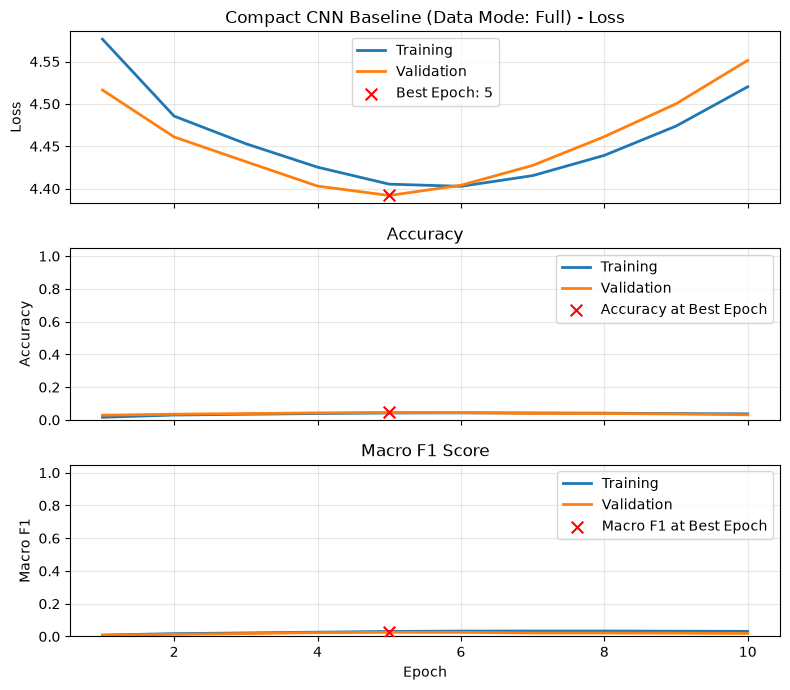


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 5
Validation Accuracy at Best Epoch: 4.54%
Validation Macro F1 at Best Epoch: 2.57%

Execution Time: 02:11:49


In [5]:
# P1.B — REQUIRED SAVED RESULTS
# Show baseline validation metrics and training/validation history or plots.

tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("full", batch_size=32)                # full mode - using 100% of the training/validation splits

baseline_model_history = train_and_validate(
    model           = baseline_model,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS,           # 50 epochs for full mode
    lr_schedule     = 1e-4,
    title           = "Compact CNN Baseline (Data Mode: Full)",
    patience        = 5,
    return_history  = True
)

**Your Answer:**

> State the baseline's primary limitation and the validation metric that will be used to compare later models. Keep metric definitions and validation samples consistent across comparisons.

The baseline's main limitation is due to its architecture not being deep or complex enough to capture the distinct relationships of the 101 food classes. While it performed better than a random guess for each image (~1% accuracy) by having an accuracy of 4.41%, the graph above shows that the training and validation accuracy and macro F1 score essentially flatlining from epochs 1 to 11. While the model was able to reach a minimum in validation loss at epoch 6, it doesn't justify the minimal improvements in terms of accuracy (main evaluation metric to compare models). The macro F1 score at the epoch with the minimum validation loss was 2.39%, still an improvement than just a random 1% choice, but it shows that the model still struggles for certain classes which the higher accuracy percentage failed to capture. For comparisons between the models in this experiment, I will record the accuracy (main evaluation metric) and macro F1 scores (secondary evaluation metric) at the epoch with minimum validation loss.

### Part C — Plan the Final Experiments (2 pts)

- Briefly describe your experimental plan for developing and comparing the custom and pretrained models.
- Identify the improvements or alternatives you intend to investigate, any practical constraints (data subset, training time, compute resources);
    - Include how you will ensure fair comparisons using consistent validation data and metrics.
- Do not use the test set for model selection.

**Your Answer:**

The experimental plan will be to see how parameters such as depth, width, and additional layers (e.g. dropout, global average pooling, etc.) perform for accurately classifying food for the 101 food classes. This experiment will focus on custom neural network architectures as well as pretrained models to see which work best for this dataset. In the notebook above, I have created a data throttle system to test my hypotheses without running on the full sets. For example, I will start with the "smoke" test to ensure the models execute. Then, I will switch to "debug" mode (uses 10% of each split) to get a glimpse of the model performance and tweak hyperparameters. Next, I will move on to the "experiment" mode (uses 25% of each split) to evaluate in general how the model will perform with a medium sized dataset (~20K images for training) and if there are any architectural or last minute parameter changes to be made. Once that is complete and I am satisfied with my experiment, I will run the models using "full" mode (uses 100% of each split) for full training and evaluation. This will improve my workflow to reduce any computational issues or errors rather than waiting for models to be trained on the full training set first for each model experiment. It also allows for a fairer comparison of models since I will go through the same process for each. To compare the models, evaluating performance will be based on the accuracy and macro F1 at the epoch with minimum validation loss. The validation set will be used rather than the test set for model selection.

## Problem 2 — Custom Neural Network and Experiments (35 pts)

- Design and train a more capable, non-pretrained neural network than the milestone baseline, using an architecture appropriate to your dataset.
- Perform at least **two documented runs/configurations** (an initial custom design and at least one intentional improvement experiment).
- The experiments should test a meaningful hypothesis, not merely change a random seed.
- Compare using **validation only**.

> **A. Architecture and implementation (12 pts)**    
> **B. Training and controlled improvement experiment (13 pts)**    
> **C. Results and interpretation (10 pts)**

### Part A — Design and Implement a Custom Model (12 pts)

**Implementation (9 pts):**
- Define and build a custom multiclass neural network trained from scratch (no pretrained weights).
- Present the model architecture, including input representation, principal layers, output layer, regularization, and model summary or equivalent.
- Design an architecture with greater representational capacity or more appropriate inductive biases than the milestone baseline.
- Clearly distinguish model components from preprocessing components.

**Rationale (3 pts):** Explain the principal architectural differences from the milestone baseline, why you chose this design, and how you expect these changes to improve representation learning or generalization.

In [6]:
# P2.A — Define the custom model architecture.
# Include a model summary or equivalent architecture inspection.

tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    layers.RandomFlip("horizontal"),                      # randomly flip some images
    layers.RandomRotation(0.08, fill_mode="reflect"),     # randomly rotate some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image
    layers.RandomZoom(0.1, fill_mode="reflect"),          # randomly zoom some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.3),
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.1),
    layers.Dense(n_classes, activation='softmax')
])

four_block_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 64)   │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 128)  │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 128)  │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 56, 56, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 56, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 56, 56, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 256)    │             

 Total params: 4,812,069 (18.36 MB)

 Trainable params: 4,807,845 (18.34 MB)

 Non-trainable params: 4,224 (16.50 KB)

In [7]:
# P2.A — REQUIRED SAVED RESULTS
# Display architecture summary and parameter counts when available.

# Display final architecture summary and parameter counts
four_block_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 64)   │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 128)  │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 128)  │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 56, 56, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 56, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 56, 56, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 256)    │             

 Total params: 4,812,069 (18.36 MB)

 Trainable params: 4,807,845 (18.34 MB)

 Non-trainable params: 4,224 (16.50 KB)

**Your Answer:**

> Explain the principal architectural differences from the milestone baseline, why you chose this design, and how you expect these changes to improve representation learning or generalization.

My hypothesis was that the baseline model was simply not deep enough to capture the complexity in distinguishing 101 food classes. I kept the rescaling and downsizing consistent with the baseline while including training data augmentation (random horizontal image flips, rotations, and zooms) to improve generalization and reduce memorization of specific image compositions. In terms of the model's architecture, I developed a four-block CNN with 2D Convolutional layers (kernel/filter size of 3x3, padding="same", use_bias=False), BatchNormalization, ReLU activations, and 2D Maximum Pooling layers (pool size of 2x2). Block 1 uses a 64 width for the single 2D Convolutional layer, while blocks 2-4 scale up to widths of 128, 256, and 512, each using two of the 2D Convolutional layer, BatchNormalization, ReLU activation sequences followed by a single 2D Maximum Pooling layer. The rationale behind this was to increase the depth and width  to let the model capture the finer details of the image such as textures, colors, etc. across the food classes. Finally, the classification head uses 2D Global Average Pooling to reduce the spatial dimensionality and parameter count, followed by Dropout(0.3) to allow for generalization, a Dense layer with a width of 256 (use_bias=False), BatchNormalization, ReLU, a second Dropout(0.1) to allow for more generalization with a lighter drop rate, and the Dense output layer with a width of 101 and softmax activation. Overall, my hypothesis is that adding two more blocks from the baseline while each block having a sequence of the 2D Convolutional layer/s, BatchNormalization layer/s, ReLU activation/s, and 2D Maximum Pooling layer will be able to more accurately distinguish between the 101 food classes while giving the model a deep/wide enough architecture to properly capture the complexities of this data.

### Part B — Train and Run a Targeted Improvement Experiment (13 pts)

**Implementation (10 pts):**

- Train the initial custom model and at least one **deliberate variant**.
  - Examples include a justified change to model capacity, regularization, augmentation, optimizer/learning rate, or learning-rate scheduling.
- Document the training configuration for each run, including loss function, optimizer, learning rate, batch size, number of epochs, and any regularization or callbacks used.
- Set reproducible configurations and use a validation-based stopping/selection strategy where appropriate.
- Record training and validation learning curves, the number of epochs actually completed, validation metrics, and approximate training time for each run.
- Use consistent validation data and a clearly stated primary metric to ensure fair comparisons.

**Experiment statement (3 pts):** State the **hypothesis** motivating your improvement experiment, identify what changed between configurations, and explain the expected benefit and any trade-offs. Your hypothesis should be independent of the observed results. **Do not use the test set.**

--- ACTIVE DATA MODE: SMOKE ---
Smoke test: Verify pipeline execution, loss reduction, and shape compatibility.
Data Fraction    : 1.0%
Batch Size       : 32
Target Epochs    : 2

Throttled Training Set   : 716 images
Throttled Validation Set : 101 images
Throttled Test Set       : 101 images

Four Block CNN (Data Mode: Smoke)

Epoch 1/2


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


23/23 ━━━━━━━━━━━━━━━━━━━━ 16s 573ms/step - accuracy: 0.0084 - loss: 4.9377 - macro_f1: 0.0069 - val_accuracy: 0.0099 - val_loss: 4.6253 - val_macro_f1: 1.9414e-04
Epoch 2/2
23/23 ━━━━━━━━━━━━━━━━━━━━ 12s 519ms/step - accuracy: 0.0279 - loss: 4.6226 - macro_f1: 0.0233 - val_accuracy: 0.0099 - val_loss: 4.6583 - val_macro_f1: 1.9414e-04
Restoring model weights from the end of the best epoch: 1.


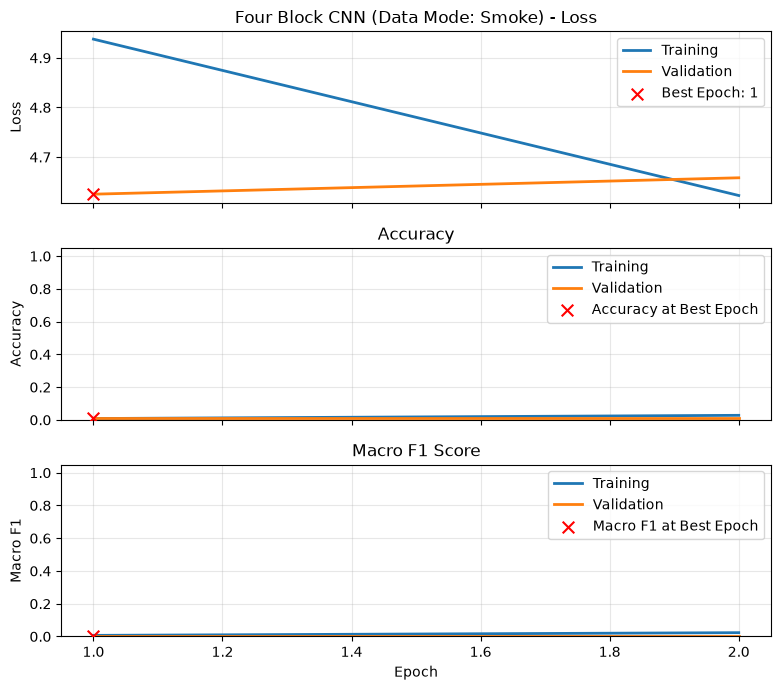


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 1
Validation Accuracy at Best Epoch: 0.99%
Validation Macro F1 at Best Epoch: 0.02%

Execution Time: 00:00:28


In [8]:
# P2.B — Train custom initial configuration and at least one deliberate variant.
# Save/history/log configurations and timing. Add more cells as needed.

# =============================
# four block CNN - "smoke" test
# =============================

# reinitalize model / seeds each time
tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("smoke", batch_size=32)               # smoke mode - using 1% of the training/validation splits

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    layers.RandomFlip("horizontal"),                      # randomly flip some images
    layers.RandomRotation(0.08, fill_mode="reflect"),     # randomly rotate some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image
    layers.RandomZoom(0.1, fill_mode="reflect"),          # randomly zoom some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.3),
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.1),
    layers.Dense(n_classes, activation='softmax')
])

four_block_cnn_smoke_history = train_and_validate(
    model           = four_block_cnn,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS,   # 2 epochs - just testing that it executes properly
    lr_schedule     = 1e-4,
    title           = "Four Block CNN (Data Mode: Smoke)",
    patience        = 3,                    
    return_history  = True
)

--- ACTIVE DATA MODE: DEBUG ---
Debugging run: Test hyperparameter tweaks and callback behavior quickly.
Data Fraction    : 10.0%
Batch Size       : 32
Target Epochs    : 5

Throttled Training Set   : 7,983 images
Throttled Validation Set : 960 images
Throttled Test Set       : 960 images

Four Block CNN (Data Mode: Debug)

Epoch 1/5


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


250/250 ━━━━━━━━━━━━━━━━━━━━ 141s 552ms/step - accuracy: 0.0246 - loss: 4.7083 - macro_f1: 0.0195 - val_accuracy: 0.0094 - val_loss: 5.2296 - val_macro_f1: 1.8564e-04
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 132s 526ms/step - accuracy: 0.0311 - loss: 4.4992 - macro_f1: 0.0242 - val_accuracy: 0.0240 - val_loss: 4.6267 - val_macro_f1: 0.0130
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 130s 519ms/step - accuracy: 0.0501 - loss: 4.3530 - macro_f1: 0.0384 - val_accuracy: 0.0469 - val_loss: 4.2603 - val_macro_f1: 0.0281
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 129s 518ms/step - accuracy: 0.0594 - loss: 4.2760 - macro_f1: 0.0473 - val_accuracy: 0.0448 - val_loss: 4.2690 - val_macro_f1: 0.0269
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 129s 518ms/step - accuracy: 0.0686 - loss: 4.1922 - macro_f1: 0.0561 - val_accuracy: 0.0594 - val_loss: 4.3307 - val_macro_f1: 0.0311
Restoring model weights from the end of the best epoch: 3.


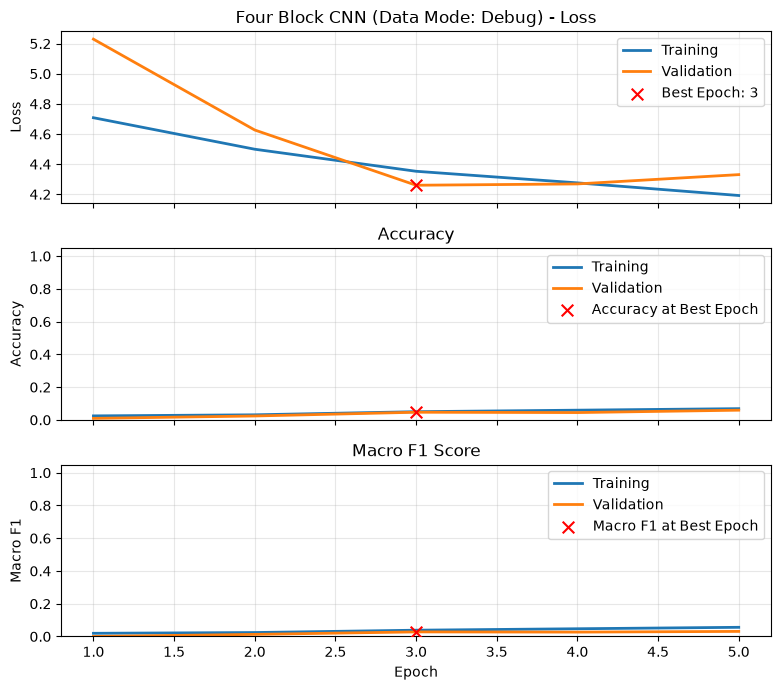


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 3
Validation Accuracy at Best Epoch: 4.69%
Validation Macro F1 at Best Epoch: 2.81%

Execution Time: 00:11:01


In [9]:
# =============================
# four block CNN - "debug" test
# =============================

# reinitalize model / seeds each time
tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("debug", batch_size=32)               # debug mode - using 10% of the training/validation splits

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    layers.RandomFlip("horizontal"),                      # randomly flip some images
    layers.RandomRotation(0.08, fill_mode="reflect"),     # randomly rotate some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image
    layers.RandomZoom(0.1, fill_mode="reflect"),          # randomly zoom some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.3),
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.1),
    layers.Dense(n_classes, activation='softmax')
])

four_block_cnn_debug_history = train_and_validate(
    model           = four_block_cnn,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS,   # 5 epochs - just testing that it executes properly
    lr_schedule     = 1e-4,
    title           = "Four Block CNN (Data Mode: Debug)",
    patience        = 3,                    
    return_history  = True
)

--- ACTIVE DATA MODE: EXPERIMENT ---
Model exploration: Evaluate architecture changes and learning rate schedules.
Data Fraction    : 25.0%
Batch Size       : 32
Target Epochs    : 15

Throttled Training Set   : 20,055 images
Throttled Validation Set : 2,475 images
Throttled Test Set       : 2,475 images

Four Block CNN (Data Mode: Experiment)

Epoch 1/15


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


627/627 ━━━━━━━━━━━━━━━━━━━━ 345s 545ms/step - accuracy: 0.0308 - loss: 4.5760 - macro_f1: 0.0247 - val_accuracy: 0.0469 - val_loss: 4.3050 - val_macro_f1: 0.0237
Epoch 2/15
627/627 ━━━━━━━━━━━━━━━━━━━━ 329s 524ms/step - accuracy: 0.0583 - loss: 4.2928 - macro_f1: 0.0454 - val_accuracy: 0.0760 - val_loss: 4.2511 - val_macro_f1: 0.0380
Epoch 3/15
627/627 ━━━━━━━━━━━━━━━━━━━━ 329s 525ms/step - accuracy: 0.0803 - loss: 4.1039 - macro_f1: 0.0634 - val_accuracy: 0.0844 - val_loss: 4.1664 - val_macro_f1: 0.0496
Epoch 4/15
627/627 ━━━━━━━━━━━━━━━━━━━━ 326s 520ms/step - accuracy: 0.1089 - loss: 3.9422 - macro_f1: 0.0879 - val_accuracy: 0.0881 - val_loss: 4.0764 - val_macro_f1: 0.0609
Epoch 5/15
627/627 ━━━━━━━━━━━━━━━━━━━━ 326s 520ms/step - accuracy: 0.1279 - loss: 3.8097 - macro_f1: 0.1053 - val_accuracy: 0.0699 - val_loss: 4.4014 - val_macro_f1: 0.0469
Epoch 6/15
627/627 ━━━━━━━━━━━━━━━━━━━━ 328s 524ms/step - accuracy: 0.1435 - loss: 3.6930 - macro_f1: 0.1206 - val_accuracy: 0.0655 - val_los

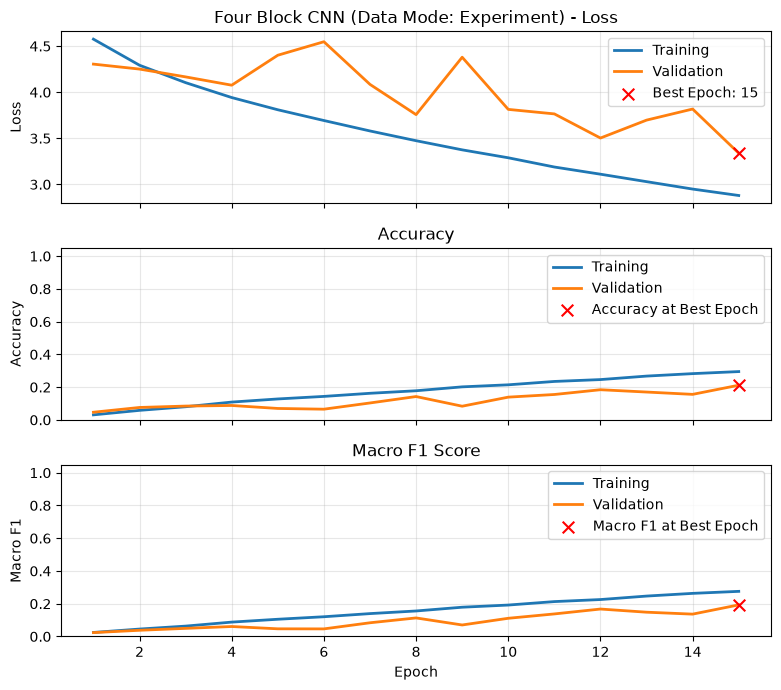


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 15
Validation Accuracy at Best Epoch: 21.17%
Validation Macro F1 at Best Epoch: 19.30%

Execution Time: 01:22:01


In [10]:
# ====================================================================================================================================================================================
# four block CNN - "experiment" test - increasing patience to 5 and epochs 15. potentially already reached minimum validation loss point, but giving model extra training time to see.
# ====================================================================================================================================================================================

# reinitalize model / seeds each time
tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("experiment", batch_size=32)          # experiment mode - using 25% of the training/validation splits

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    layers.RandomFlip("horizontal"),                      # randomly flip some images
    layers.RandomRotation(0.08, fill_mode="reflect"),     # randomly rotate some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image
    layers.RandomZoom(0.1, fill_mode="reflect"),          # randomly zoom some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.3),
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.1),
    layers.Dense(n_classes, activation='softmax')
])

four_block_cnn_experiment_history = train_and_validate(
    model           = four_block_cnn,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS,                   # 15 epochs - testing hyperparameters and final architecture changes
    lr_schedule     = 1e-4,
    title           = "Four Block CNN (Data Mode: Experiment)",
    patience        = 5,                                    # changed from 3 (from "debug" test) to 5                    
    return_history  = True
)

--- ACTIVE DATA MODE: EXPERIMENT ---
Model exploration: Evaluate architecture changes and learning rate schedules.
Data Fraction    : 25.0%
Batch Size       : 32
Target Epochs    : 15

Throttled Training Set   : 20,055 images
Throttled Validation Set : 2,475 images
Throttled Test Set       : 2,475 images

Four Block CNN w Increased Dropout (Data Mode: Experiment)

Epoch 1/15


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


627/627 ━━━━━━━━━━━━━━━━━━━━ 331s 523ms/step - accuracy: 0.0239 - loss: 4.6643 - macro_f1: 0.0205 - val_accuracy: 0.0457 - val_loss: 4.3830 - val_macro_f1: 0.0188
Epoch 2/15
627/627 ━━━━━━━━━━━━━━━━━━━━ 329s 525ms/step - accuracy: 0.0458 - loss: 4.4097 - macro_f1: 0.0354 - val_accuracy: 0.0651 - val_loss: 4.2685 - val_macro_f1: 0.0340
Epoch 3/15
627/627 ━━━━━━━━━━━━━━━━━━━━ 330s 526ms/step - accuracy: 0.0641 - loss: 4.2402 - macro_f1: 0.0511 - val_accuracy: 0.0840 - val_loss: 4.1331 - val_macro_f1: 0.0503
Epoch 4/15
627/627 ━━━━━━━━━━━━━━━━━━━━ 328s 524ms/step - accuracy: 0.0852 - loss: 4.0811 - macro_f1: 0.0682 - val_accuracy: 0.0776 - val_loss: 4.1187 - val_macro_f1: 0.0448
Epoch 5/15
627/627 ━━━━━━━━━━━━━━━━━━━━ 326s 520ms/step - accuracy: 0.1015 - loss: 3.9681 - macro_f1: 0.0818 - val_accuracy: 0.0683 - val_loss: 4.2670 - val_macro_f1: 0.0367
Epoch 6/15
627/627 ━━━━━━━━━━━━━━━━━━━━ 327s 522ms/step - accuracy: 0.1175 - loss: 3.8574 - macro_f1: 0.0972 - val_accuracy: 0.1123 - val_los

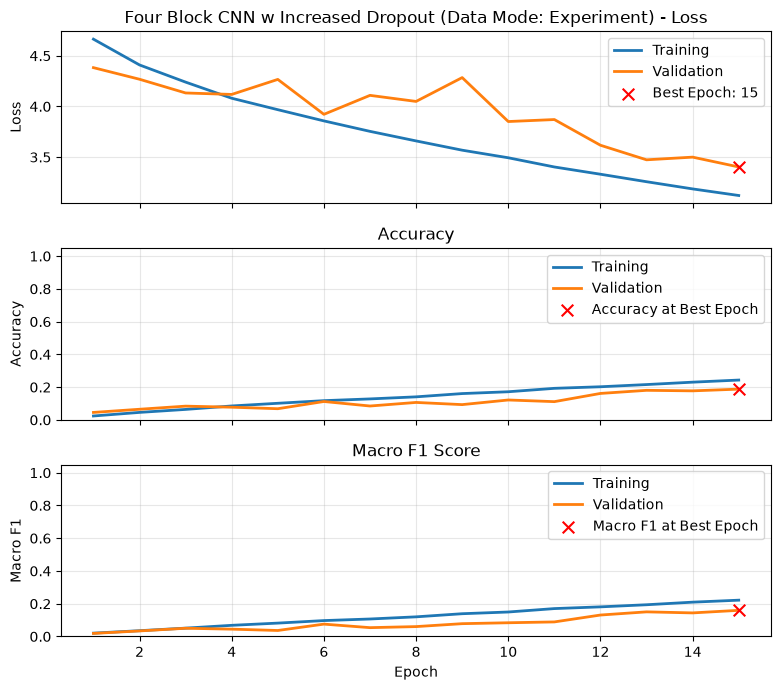


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 15
Validation Accuracy at Best Epoch: 18.79%
Validation Macro F1 at Best Epoch: 15.98%

Execution Time: 01:21:59


In [11]:
# ====================================================================================================================================================================================
# four block CNN - "experiment" test - increasing dropout from previous experiment run to try to improve generalization/accuracy 
# ====================================================================================================================================================================================

# reinitalize model / seeds each time
tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("experiment", batch_size=32)          # experiment mode - using 25% of the training/validation splits

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    layers.RandomFlip("horizontal"),                      # randomly flip some images
    layers.RandomRotation(0.08, fill_mode="reflect"),     # randomly rotate some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image
    layers.RandomZoom(0.1, fill_mode="reflect"),          # randomly zoom some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.4),                                   # changed from 0.3 to 0.4
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.2),                                   # changed from 0.1 to 0.2
    layers.Dense(n_classes, activation='softmax')
])

# V2: increased dropout in classification head (V1: 0.3 and 0.1 | V2: 0.4 and 0.2)
four_block_cnn_experiment_v2_history = train_and_validate(
    model           = four_block_cnn,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS,                   # 15 epochs - testing hyperparameters and final architecture changes
    lr_schedule     = 1e-4,
    title           = "Four Block CNN w Increased Dropout (Data Mode: Experiment)",
    patience        = 5,                                                        
    return_history  = True
)

--- ACTIVE DATA MODE: EXPERIMENT ---
Model exploration: Evaluate architecture changes and learning rate schedules.
Data Fraction    : 25.0%
Batch Size       : 48
Target Epochs    : 15

Throttled Training Set   : 20,055 images
Throttled Validation Set : 2,475 images
Throttled Test Set       : 2,475 images

Four Block CNN w 48 Batch Size (Data Mode: Experiment)

Epoch 1/15


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


418/418 ━━━━━━━━━━━━━━━━━━━━ 333s 788ms/step - accuracy: 0.0333 - loss: 4.5852 - macro_f1: 0.0276 - val_accuracy: 0.0190 - val_loss: 5.1288 - val_macro_f1: 0.0047
Epoch 2/15
418/418 ━━━━━━━━━━━━━━━━━━━━ 330s 788ms/step - accuracy: 0.0564 - loss: 4.3287 - macro_f1: 0.0444 - val_accuracy: 0.0776 - val_loss: 4.1943 - val_macro_f1: 0.0463
Epoch 3/15
418/418 ━━━━━━━━━━━━━━━━━━━━ 327s 782ms/step - accuracy: 0.0811 - loss: 4.1407 - macro_f1: 0.0636 - val_accuracy: 0.0739 - val_loss: 4.1675 - val_macro_f1: 0.0502
Epoch 4/15
418/418 ━━━━━━━━━━━━━━━━━━━━ 326s 779ms/step - accuracy: 0.1028 - loss: 3.9855 - macro_f1: 0.0809 - val_accuracy: 0.0638 - val_loss: 4.3514 - val_macro_f1: 0.0448
Epoch 5/15
418/418 ━━━━━━━━━━━━━━━━━━━━ 326s 780ms/step - accuracy: 0.1187 - loss: 3.8597 - macro_f1: 0.0963 - val_accuracy: 0.1038 - val_loss: 4.0078 - val_macro_f1: 0.0748
Epoch 6/15
418/418 ━━━━━━━━━━━━━━━━━━━━ 326s 779ms/step - accuracy: 0.1394 - loss: 3.7420 - macro_f1: 0.1164 - val_accuracy: 0.0739 - val_los

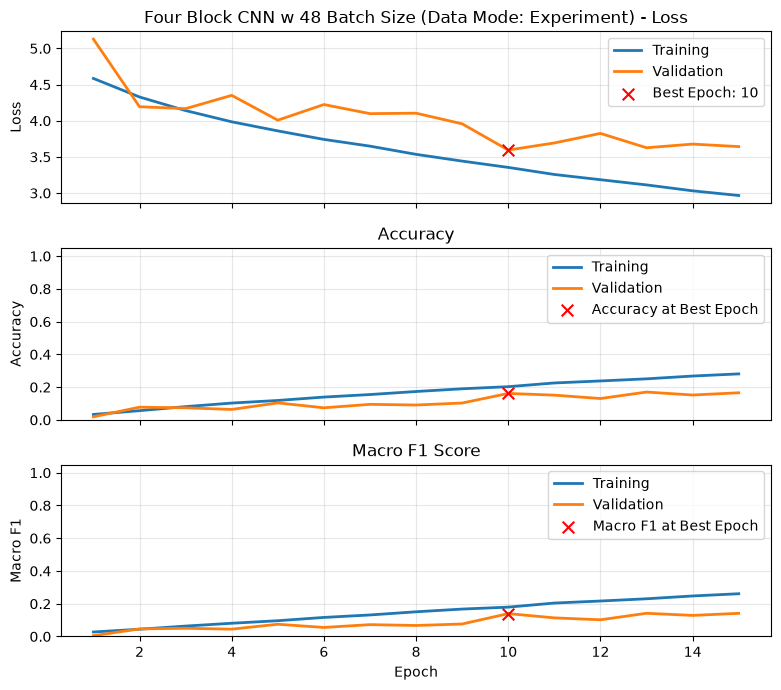


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 10
Validation Accuracy at Best Epoch: 16.16%
Validation Macro F1 at Best Epoch: 13.97%

Execution Time: 01:21:54


In [12]:
# ===========================================================
# four block CNN - "experiment" test - larger batch size (48)
# ===========================================================

# reinitalize model / seeds each time
tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("experiment", batch_size=48)          # experiment mode - using 25% of the training/validation splits

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    layers.RandomFlip("horizontal"),                      # randomly flip some images
    layers.RandomRotation(0.08, fill_mode="reflect"),     # randomly rotate some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image
    layers.RandomZoom(0.1, fill_mode="reflect"),          # randomly zoom some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.3),
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.1),
    layers.Dense(n_classes, activation='softmax')
])

four_block_cnn_experiment_v3_history = train_and_validate(
    model           = four_block_cnn,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS,                   # 15 epochs - testing hyperparameters and final architecture changes
    lr_schedule     = 1e-4,
    title           = "Four Block CNN w 48 Batch Size (Data Mode: Experiment)",
    patience        = 5,                                    # changed from 3 (from "debug" test) to 5                    
    return_history  = True
)

The training loss is dropping steadily as the validation hovers above with more rigidity. It seems like since the accuracy and macro f1 is still steadily increasing for training and validation that the model hasn't converged yet. Next, I'll run the model with "experiment" mode with cosine decay and 10 extra epochs (25 total). My hope is that it will converge more and see how if overfitting starts to take over.

--- ACTIVE DATA MODE: EXPERIMENT ---
Model exploration: Evaluate architecture changes and learning rate schedules.
Data Fraction    : 25.0%
Batch Size       : 48
Target Epochs    : 15

Throttled Training Set   : 20,055 images
Throttled Validation Set : 2,475 images
Throttled Test Set       : 2,475 images

Four Block CNN w 48 Batch Size & Cosine Decay (Data Mode: Experiment)

Epoch 1/25


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


418/418 ━━━━━━━━━━━━━━━━━━━━ 343s 814ms/step - accuracy: 0.0224 - loss: 4.6106 - macro_f1: 0.0175 - val_accuracy: 0.0246 - val_loss: 4.5483 - val_macro_f1: 0.0092
Epoch 2/25
418/418 ━━━━━━━━━━━━━━━━━━━━ 332s 794ms/step - accuracy: 0.0425 - loss: 4.3729 - macro_f1: 0.0316 - val_accuracy: 0.0331 - val_loss: 4.8761 - val_macro_f1: 0.0138
Epoch 3/25
418/418 ━━━━━━━━━━━━━━━━━━━━ 330s 789ms/step - accuracy: 0.0620 - loss: 4.1924 - macro_f1: 0.0464 - val_accuracy: 0.0521 - val_loss: 4.4248 - val_macro_f1: 0.0270
Epoch 4/25
418/418 ━━━━━━━━━━━━━━━━━━━━ 332s 795ms/step - accuracy: 0.0844 - loss: 4.0145 - macro_f1: 0.0638 - val_accuracy: 0.0586 - val_loss: 4.4344 - val_macro_f1: 0.0272
Epoch 5/25
418/418 ━━━━━━━━━━━━━━━━━━━━ 334s 799ms/step - accuracy: 0.1120 - loss: 3.8512 - macro_f1: 0.0895 - val_accuracy: 0.0695 - val_loss: 4.4722 - val_macro_f1: 0.0425
Epoch 6/25
418/418 ━━━━━━━━━━━━━━━━━━━━ 331s 790ms/step - accuracy: 0.1354 - loss: 3.6904 - macro_f1: 0.1125 - val_accuracy: 0.0816 - val_los

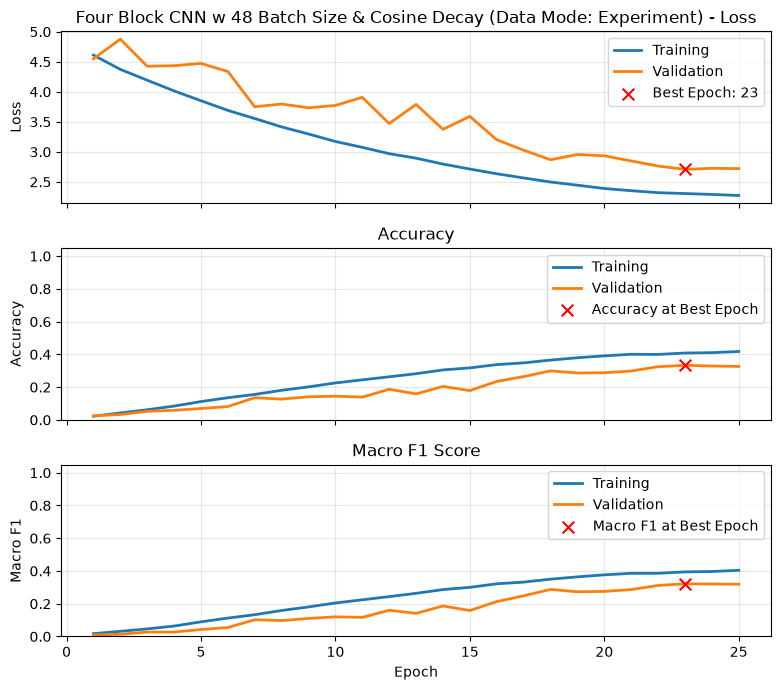


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 23
Validation Accuracy at Best Epoch: 33.33%
Validation Macro F1 at Best Epoch: 32.18%

Execution Time: 02:18:06


In [13]:
# ===========================================================================================
# four block CNN - "experiment" test with 25 epochs - larger batch size (48) and cosine decay
# ===========================================================================================

# reinitalize model / seeds each time
tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("experiment", batch_size=48)          # experiment mode - using 25% of the training/validation splits

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    layers.RandomFlip("horizontal"),                      # randomly flip some images
    layers.RandomRotation(0.08, fill_mode="reflect"),     # randomly rotate some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image
    layers.RandomZoom(0.1, fill_mode="reflect"),          # randomly zoom some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.3),
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.1),
    layers.Dense(n_classes, activation='softmax')
])

# calculate decay steps
total_epochs    = RECOMMENDED_EPOCHS + 10
steps_per_epoch = int(tf.data.experimental.cardinality(train_tf).numpy())
decay_steps     = total_epochs * steps_per_epoch

cosine_decay = CosineDecay(
    initial_learning_rate   = 1e-3,         # higher LR to start with
    decay_steps             = decay_steps,
    alpha                   = 0.01
)

four_block_cnn_experiment_v4_history = train_and_validate(
    model           = four_block_cnn,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS + 10,                                                  # 25 epochs - testing hyperparameters and final architecture changes
    lr_schedule     = cosine_decay,                                                             # increased from 1e-4 to 1e-3 to allow for decay to kick in
    title           = "Four Block CNN w 48 Batch Size & Cosine Decay (Data Mode: Experiment)",
    patience        = 5,                                                                        # changed from 3 (from "debug" test) to 5
    return_history  = True
)

--- ACTIVE DATA MODE: FULL ---
Production run: Full training for final evaluation and recording results.
Data Fraction    : 100.0%
Batch Size       : 32
Target Epochs    : 50

Throttled Training Set   : 80,382 images
Throttled Validation Set : 10,048 images
Throttled Test Set       : 10,048 images

Four Block CNN (Data Mode: Full)

Epoch 1/50


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2512/2512 ━━━━━━━━━━━━━━━━━━━━ 1408s 559ms/step - accuracy: 0.0695 - loss: 4.2338 - macro_f1: 0.0561 - val_accuracy: 0.0907 - val_loss: 4.0697 - val_macro_f1: 0.0642
Epoch 2/50
2512/2512 ━━━━━━━━━━━━━━━━━━━━ 1415s 563ms/step - accuracy: 0.1469 - loss: 3.6843 - macro_f1: 0.1243 - val_accuracy: 0.1390 - val_loss: 3.7351 - val_macro_f1: 0.1133
Epoch 3/50
2512/2512 ━━━━━━━━━━━━━━━━━━━━ 1410s 561ms/step - accuracy: 0.2104 - loss: 3.3218 - macro_f1: 0.1880 - val_accuracy: 0.1774 - val_loss: 3.4521 - val_macro_f1: 0.1651
Epoch 4/50
2512/2512 ━━━━━━━━━━━━━━━━━━━━ 1418s 564ms/step - accuracy: 0.2629 - loss: 3.0466 - macro_f1: 0.2432 - val_accuracy: 0.1300 - val_loss: 4.0522 - val_macro_f1: 0.1161
Epoch 5/50
2512/2512 ━━━━━━━━━━━━━━━━━━━━ 1419s 565ms/step - accuracy: 0.3056 - loss: 2.8315 - macro_f1: 0.2887 - val_accuracy: 0.1831 - val_loss: 3.5985 - val_macro_f1: 0.1657
Epoch 6/50
2512/2512 ━━━━━━━━━━━━━━━━━━━━ 1419s 565ms/step - accuracy: 0.3417 - loss: 2.6590 - macro_f1: 0.3270 - val_accuracy

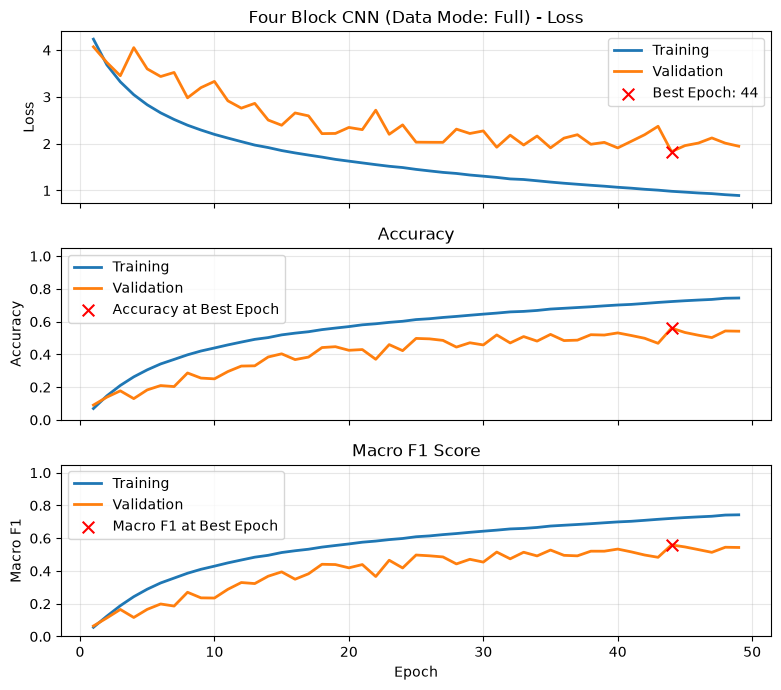


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 44
Validation Accuracy at Best Epoch: 56.03%
Validation Macro F1 at Best Epoch: 55.91%

Execution Time: 19:03:49


In [14]:
# ============================================
# four block CNN - "full" test (32 Batch Size)
# ============================================

# reinitalize model / seeds each time
tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("full", batch_size=32)                # full mode - using 100% of the training/validation splits

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    layers.RandomFlip("horizontal"),                      # randomly flip some images
    layers.RandomRotation(0.08, fill_mode="reflect"),     # randomly rotate some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image
    layers.RandomZoom(0.1, fill_mode="reflect"),          # randomly zoom some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.3),
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.1),
    layers.Dense(n_classes, activation='softmax')
])

four_block_cnn_full_history = train_and_validate(
    model           = four_block_cnn,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS,                   # 50 epochs - full training set
    lr_schedule     = 1e-4,
    title           = "Four Block CNN (Data Mode: Full)",
    patience        = 5,                                                       
    return_history  = True
)

--- ACTIVE DATA MODE: FULL ---
Production run: Full training for final evaluation and recording results.
Data Fraction    : 100.0%
Batch Size       : 48
Target Epochs    : 50

Throttled Training Set   : 80,382 images
Throttled Validation Set : 10,048 images
Throttled Test Set       : 10,048 images

Four Block CNN w Batch Size 48 (Data Mode: Full)

Epoch 1/50


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1397s 831ms/step - accuracy: 0.0710 - loss: 4.2474 - macro_f1: 0.0570 - val_accuracy: 0.0917 - val_loss: 4.0332 - val_macro_f1: 0.0678
Epoch 2/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1390s 829ms/step - accuracy: 0.1427 - loss: 3.7235 - macro_f1: 0.1198 - val_accuracy: 0.1457 - val_loss: 3.6641 - val_macro_f1: 0.1192
Epoch 3/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1382s 825ms/step - accuracy: 0.2023 - loss: 3.3728 - macro_f1: 0.1798 - val_accuracy: 0.1888 - val_loss: 3.4290 - val_macro_f1: 0.1746
Epoch 4/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1382s 825ms/step - accuracy: 0.2573 - loss: 3.0920 - macro_f1: 0.2369 - val_accuracy: 0.1378 - val_loss: 3.8509 - val_macro_f1: 0.1228
Epoch 5/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1379s 823ms/step - accuracy: 0.3001 - loss: 2.8782 - macro_f1: 0.2823 - val_accuracy: 0.2288 - val_loss: 3.1931 - val_macro_f1: 0.2161
Epoch 6/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1380s 824ms/step - accuracy: 0.3336 - loss: 2.7027 - macro_f1: 0.3184 - val_accuracy

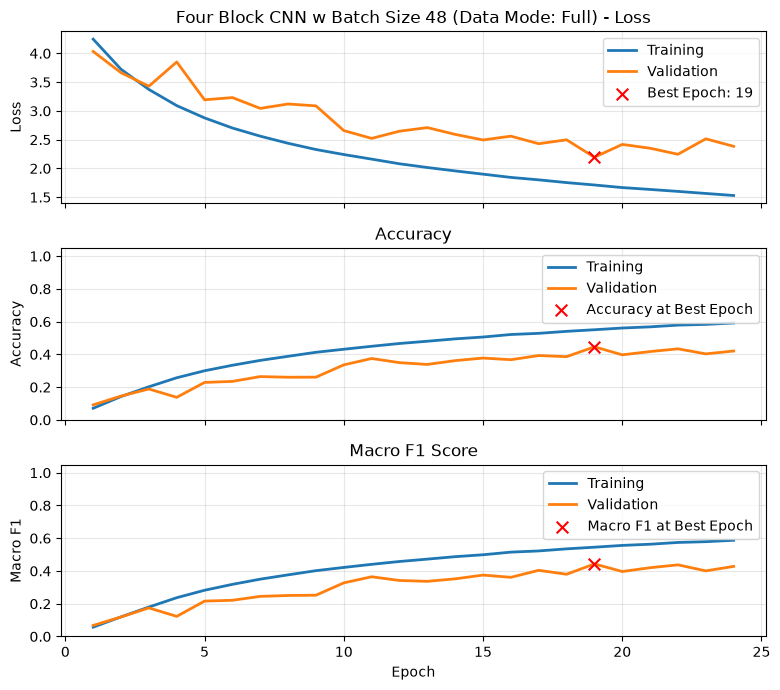


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 19
Validation Accuracy at Best Epoch: 44.63%
Validation Macro F1 at Best Epoch: 44.30%

Execution Time: 09:13:39


In [15]:
# ============================================
# four block CNN - "full" test (48 Batch Size)
# ============================================

# reinitalize model / seeds each time
tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("full", batch_size=48)                # full mode - using 100% of the training/validation splits

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    layers.RandomFlip("horizontal"),                      # randomly flip some images
    layers.RandomRotation(0.08, fill_mode="reflect"),     # randomly rotate some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image
    layers.RandomZoom(0.1, fill_mode="reflect"),          # randomly zoom some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.3),
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.1),
    layers.Dense(n_classes, activation='softmax')
])

four_block_cnn_full_v2_history = train_and_validate(
    model           = four_block_cnn,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS,                   # 50 epochs - full training set
    lr_schedule     = 1e-4,
    title           = "Four Block CNN w Batch Size 48 (Data Mode: Full)",
    patience        = 5,                                                       
    return_history  = True
)

--- ACTIVE DATA MODE: FULL ---
Production run: Full training for final evaluation and recording results.
Data Fraction    : 100.0%
Batch Size       : 48
Target Epochs    : 50

Throttled Training Set   : 80,382 images
Throttled Validation Set : 10,048 images
Throttled Test Set       : 10,048 images

Four Block CNN w 48 Batch Size & Cosine Decay (Data Mode: Full)

Epoch 1/50


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1390s 828ms/step - accuracy: 0.0560 - loss: 4.2829 - macro_f1: 0.0437 - val_accuracy: 0.0524 - val_loss: 4.5077 - val_macro_f1: 0.0333
Epoch 2/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1393s 832ms/step - accuracy: 0.1384 - loss: 3.6783 - macro_f1: 0.1164 - val_accuracy: 0.0837 - val_loss: 4.4220 - val_macro_f1: 0.0620
Epoch 3/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1397s 834ms/step - accuracy: 0.2197 - loss: 3.2267 - macro_f1: 0.1986 - val_accuracy: 0.1386 - val_loss: 3.8329 - val_macro_f1: 0.1255
Epoch 4/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1393s 831ms/step - accuracy: 0.2908 - loss: 2.8759 - macro_f1: 0.2732 - val_accuracy: 0.1653 - val_loss: 3.8371 - val_macro_f1: 0.1461
Epoch 5/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1397s 834ms/step - accuracy: 0.3474 - loss: 2.6089 - macro_f1: 0.3338 - val_accuracy: 0.2370 - val_loss: 3.2262 - val_macro_f1: 0.2177
Epoch 6/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1391s 830ms/step - accuracy: 0.3921 - loss: 2.3965 - macro_f1: 0.3814 - val_accuracy

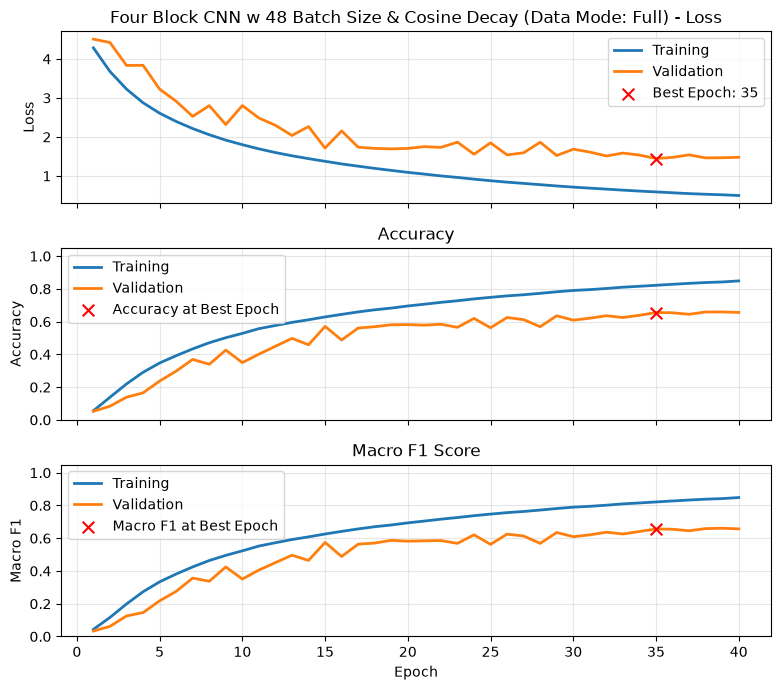


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 35
Validation Accuracy at Best Epoch: 65.57%
Validation Macro F1 at Best Epoch: 65.68%

Execution Time: 15:21:11


In [16]:
# =====================================================================================
# four block CNN - "full" test with 50 epochs - larger batch size (48) and cosine decay
# =====================================================================================

# reinitalize model / seeds each time
tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("full", batch_size=48)                # full mode - using 100% of the training/validation splits

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    layers.RandomFlip("horizontal"),                      # randomly flip some images
    layers.RandomRotation(0.08, fill_mode="reflect"),     # randomly rotate some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image
    layers.RandomZoom(0.1, fill_mode="reflect"),          # randomly zoom some images - uses reflect fill mode to fill out of bounds pixels by mirroring the image

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.3),
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.1),
    layers.Dense(n_classes, activation='softmax')
])

# calculate decay steps
total_epochs    = RECOMMENDED_EPOCHS
steps_per_epoch = int(tf.data.experimental.cardinality(train_tf).numpy())
decay_steps     = total_epochs * steps_per_epoch

cosine_decay = CosineDecay(
    initial_learning_rate   = 1e-3,         # higher LR to start with
    decay_steps             = decay_steps,
    alpha                   = 0.01
)

four_block_cnn_full_v3_history = train_and_validate(
    model           = four_block_cnn,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS,                                                       # 50 epochs - testing hyperparameters and final architecture changes
    lr_schedule     = cosine_decay,                                                             # increased from 1e-4 to 1e-3 to allow for decay to kick in
    title           = "Four Block CNN w 48 Batch Size & Cosine Decay (Data Mode: Full)",
    patience        = 5,                                                                        
    return_history  = True
)

--- ACTIVE DATA MODE: FULL ---
Production run: Full training for final evaluation and recording results.
Data Fraction    : 100.0%
Batch Size       : 48
Target Epochs    : 50

Throttled Training Set   : 80,382 images
Throttled Validation Set : 10,048 images
Throttled Test Set       : 10,048 images

Four Block CNN w 48 Batch Size & Cosine Decay w/o Data Aug. (Data Mode: Full)

Epoch 1/50


/opt/anaconda3/envs/tf_mac/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1368s 814ms/step - accuracy: 0.0624 - loss: 4.2510 - macro_f1: 0.0483 - val_accuracy: 0.0759 - val_loss: 4.1611 - val_macro_f1: 0.0544
Epoch 2/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1359s 811ms/step - accuracy: 0.1554 - loss: 3.5882 - macro_f1: 0.1318 - val_accuracy: 0.1582 - val_loss: 3.5849 - val_macro_f1: 0.1315
Epoch 3/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1336s 797ms/step - accuracy: 0.2450 - loss: 3.0961 - macro_f1: 0.2249 - val_accuracy: 0.1704 - val_loss: 3.6719 - val_macro_f1: 0.1531
Epoch 4/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1349s 805ms/step - accuracy: 0.3149 - loss: 2.7454 - macro_f1: 0.2994 - val_accuracy: 0.2358 - val_loss: 3.2659 - val_macro_f1: 0.2072
Epoch 5/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1343s 802ms/step - accuracy: 0.3752 - loss: 2.4716 - macro_f1: 0.3630 - val_accuracy: 0.1185 - val_loss: 5.1358 - val_macro_f1: 0.1163
Epoch 6/50
1675/1675 ━━━━━━━━━━━━━━━━━━━━ 1351s 807ms/step - accuracy: 0.4249 - loss: 2.2449 - macro_f1: 0.4153 - val_accuracy

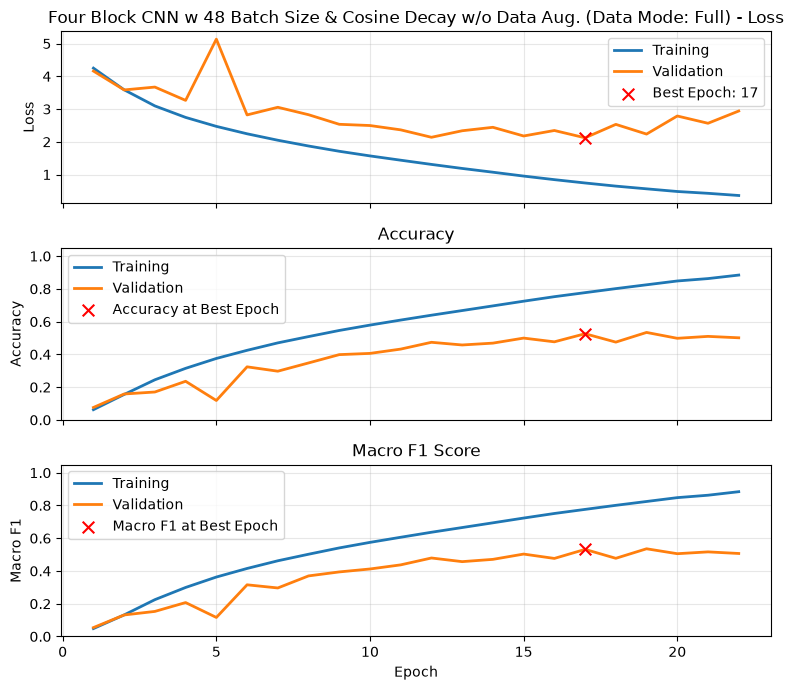


--- Training & Validation Summary ---
Best Epoch (Min Val Loss): 17
Validation Accuracy at Best Epoch: 52.61%
Validation Macro F1 at Best Epoch: 53.17%

Execution Time: 08:13:01


In [36]:
# =============================================================================================================================================
# four block CNN - "full" test with 50 epochs - larger batch size (48) and cosine decay - WITHOUT DATA AUGMENTATION (EXCEPT RESIZING/RESCALING)
# =============================================================================================================================================

# reinitalize model / seeds each time
tf.keras.backend.clear_session()                    # clear keras graph and memory
tf.keras.utils.set_random_seed(random_seed)         # sets Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()      # controls hardware execution order for reproducible floating points

set_data_mode("full", batch_size=48)                # full mode - using 100% of the training/validation splits

n_classes = len(train.features['label'].names)      # classes for each split already verified to be the same
four_block_cnn = models.Sequential([

    # 512x512 image with 3 channels: RGB
    layers.Input(shape=(512, 512, 3)),

    # normalize pixel values to [0, 1]
    layers.Rescaling(scale=1.0 / 255.0),

    # downscale image sizes
    layers.Resizing(224, 224),

    # first block
    layers.Conv2D(64, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # second block
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(128, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # third block
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(256, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # forth block
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.Conv2D(512, (3, 3), padding='same', use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # classification head
    layers.GlobalAveragePooling2D(),
    Dropout(0.3),
    layers.Dense(256, use_bias=False),
    BatchNormalization(),
    layers.Activation('relu'),
    Dropout(0.1),
    layers.Dense(n_classes, activation='softmax')
])

# calculate decay steps
total_epochs    = RECOMMENDED_EPOCHS
steps_per_epoch = int(tf.data.experimental.cardinality(train_tf).numpy())
decay_steps     = total_epochs * steps_per_epoch

cosine_decay = CosineDecay(
    initial_learning_rate   = 1e-3,         # higher LR to start with
    decay_steps             = decay_steps,
    alpha                   = 0.01
)

four_block_cnn_full_v4_history = train_and_validate(
    model           = four_block_cnn,
    train_data      = train_tf,
    val_data        = val_tf,
    epochs          = RECOMMENDED_EPOCHS,                                                       # 50 epochs - testing hyperparameters and final architecture changes
    lr_schedule     = cosine_decay,                                                             # increased from 1e-4 to 1e-3 to allow for decay to kick in
    title           = "Four Block CNN w 48 Batch Size & Cosine Decay w/o Data Aug. (Data Mode: Full)",
    patience        = 5,                                                                        
    return_history  = True
)

In [ ]:
# Save results in order to not have to re-run entire notebook
results = get_model_leaderboard().copy()
results.to_csv('part_2_results_with_baseline.csv', index=False)

In [3]:
# P2.B — REQUIRED SAVED RESULTS
# Show a concise run table, validation metrics, learning curves, and runtime.

results = pd.read_csv('part_2_results_with_baseline.csv')     # uncomment to see saved results without running all models again
results

# display(get_model_leaderboard())

,model_title,data_mode,batch_size,best_epoch,val_accuracy_pct,val_macro_f1_pct,execution_time
0,Four Block CNN w 48 Batch Size & Cosine Decay ...,full,48,35,65.57,65.68,15:21:11
1,Four Block CNN (Data Mode: Full),full,32,44,56.03,55.91,19:03:49
2,Four Block CNN w 48 Batch Size & Cosine Decay ...,full,48,17,52.61,53.17,08:13:01
3,Four Block CNN w Batch Size 48 (Data Mode: Full),full,48,19,44.63,44.30,09:13:39
4,Four Block CNN w 48 Batch Size & Cosine Decay ...,experiment,48,23,33.33,32.18,02:18:06
5,Four Block CNN (Data Mode: Experiment),experiment,32,15,21.17,19.30,01:22:01
6,Four Block CNN w Increased Dropout (Data Mode:...,experiment,32,15,18.79,15.98,01:21:59
7,Four Block CNN w 48 Batch Size (Data Mode: Exp...,experiment,48,10,16.16,13.97,01:21:54
8,Four Block CNN (Data Mode: Debug),debug,32,3,4.69,2.81,00:11:01
9,Compact CNN Baseline (Data Mode: Full),full,32,5,4.54,2.57,02:11:49


**Your Answer:**

> State the hypothesis motivating your improvement experiment, identify what changed between configurations, and explain the expected benefit and any trade-offs.

My first hypothesis motivating the experiment was to determine the best learning rate and batch size for the four-block CNN architecture. I first analyzed the model performance running a quick "smoke" test (1% of training/validation sets with just 2 epochs) to ensure it compiles, then change the data mode to "debug" (10% of training/validation sets with 5 epochs) to see if I am satisfied with the baseline hyperparameters (learning rate and batch size). In the "debug" mode, I found that the model reached its minimum validation loss at epoch 3 with a validation accuracy of 4.69% and a validation macro F1 of 2.81%, meaning the model is performing better than a random 1/101 choice to classify the food images. Now that the general architecture and hyperparameters seem like a good fit for this dataset, I ran the same architecture on "experiment" mode (25% of training/validation sets with 15 epochs) and a higher patience of 5 in order to give the model extra training time to see if performance improves. The improvement was very significant because after 15 epochs the model reached a validation accuracy of 21.17% and a validation macro F1 of 19.30%. However, the validation loss was very spiky with a downward trend. My first attempt to reduce this issue was the increase the dropout rates in the classification head (0.3 to 0.4 and 0.1 to 0.2). The idea was that it could improve generalization of the model with less complexity in the final tensors before going through the dense classification softmax layer. Keeping the data mode set at "experiment", the model reached its minimum validation loss at epoch 15 again but with a validation accuracy and macro F1 of 18.79% and 15.98% respectively. The validation loss curves were much less jagged which was a good sign, but the reduction in validation accuracy and macro F1 led me to not implement those dropout increases for the model architecture. My second hypothesis during the "experiment" mode runs was that batch size could improve the jagged validation loss curves. I increased the batch size from 32 to 48, which resulted in smoother validation loss curves and the model reaching its minimum validation loss at epoch 10 instead of epoch 15. It had a validation accuracy and macro F1 of 16.16% and 13.97% respectively. Since this was still not an improvement from the regular "experiment" mode model with the original architecture design (21.17% validation accuracy and 19.30% validation macro F1), my next hypothesis was that a non-linear learning rate schedule could improve the evaluation metrics. I stuck with the 48 batch size since it smoothed out the validation loss curve while introducing cosine decay as a learning rate scheduler (initial learning rate of 1e-3 vs. original 1e-4 to allow for decay over time). In order to allow for the learning rate to decay, I gave it an extra 10 epochs if needed while maintaining the original 5 epoch patience as the other models in "experiment" mode. This model reached its minimum validation loss at epoch 23 with validation accuracy and macro F1 of 33.33% and 32.18% respectively, a significant improvement from the original archtecture design (21.17% validation accuracy and 19.30% validation macro F1). My hypothesis ended up being true. 

Next step was to do final tests by running 4 tests on "full" mode (100% of training and validation sets with 50 epochs) to ensure that my experiments in "experiment" mode held up on the entire training and validation sets. The four tests were the original architecture with 32 batch size and a learning rate of 1e-4, original architecture with 48 batch size and a learning rate of 1e-4, original architecture with 48 batch size and cosine decay (initial learning rate of 1e-3), and the original architecture with a 48 batch size and cosine decay (initial learning rate of 1e-3) without data augmentation (random horizontal flips, random rotations, random zooms) except for normalizing pixel values to be floating points from 0-1 and resizing the image size to 224x224. My rationale is to ensure the trends from the "experiment" mode maintain with more data as well as seeing the potential affect in performance from removing data augmentation methods in the pipeline. 

The four-block CNN with 32 batch size reached its minimum validation loss at epoch 44 with a validation accuracy and macro F1 of 56.03% and 55.91% respectively. It seems as though there is still potential for the model to reach its peak in accuracy and macro F1, but the extra training time may not be worth it since this model took 19:03:49 to complete. Interestingly, the four-block CNN with 48 batch size reached its minimum validation loss at epoch 19 with a validation accuracy and macro F1 fo 44.63% and 44.30% respectively. Though the model is less accurate, the fact that validation accuracy and macro F1 are extremely similar means that this model is much better with accurate classifications overall and the average of each classes. It also ran for 9:13:39 which is significantly faster and less computationally expensive. The four-block CNN with 48 batch size and cosine decay (initial learning rate of 1e-3) ran for 15:21:11 and reached its minimum validation loss at epoch 35 with a validation accuracy and macro F1 of 65.57% and 65.68% respectively. This model performs significantly better than the previous two models while also having the smallest absolute gap in validation accuracy and macro F1 (1st model: 0.12%, 2nd model: 0.33%, 3rd model: 0.11%) which shows that not only is the overall accuracy better, it performs well for each class on average. The trade off with this third model is that it takes longer to train for its strong performance. Finally, the four-block CNN with 48 batch size and cosine decay (initial learning rate of 1e-3) without data augmentation except for normalizing pixel values and rescaling images to 224x224 ran for 8:13:01 and reached its minimum validation loss at epoch 17 with a validation accuracy and macro F1 of 52.61% and 53.17% respectively. This was a promising model because it had a relatively high validation accuracy and macro F1 while training significantly quicker than all other models (and reached minimum at epoch 17). The slight increase in macro F1 compared to accuracy means it performs better for some classes compared to others which results in a higher average. The trade-off is a slight reduction in model performance but significantly faster training time. At large scale, this custom model may be preferred to the other design choices.

### Part C — Analyze Custom Model Results (10 pts)

**Results (6 pts):**

- Present an organized, side-by-side **validation comparison** of the milestone baseline, initial custom network, and improved custom network.
  - Include the primary selection metric, at least one supporting metric, and relevant training/validation learning curves.
  - Clearly identify the experimental configurations being compared.
- Identify the best custom configuration using the previously declared selection metric. **Do not use test results for model selection.**

**Interpretation (4 pts):**

- Evaluate whether your improvement hypothesis was supported by the validation results, citing specific evidence.
- Discuss evidence of underfitting or overfitting, generalization, and any trade-offs between model performance and computational cost.
- Explain what you learned about model architecture, training, or optimization and how these findings will inform your subsequent experiments.
- If the custom models did not outperform the milestone baseline, explain what the results suggest rather than concealing or dismissing the outcome.

In [8]:
# P2.C — Compare validation results.
# Create a table comparing the milestone baseline,
# initial custom network, and improved custom network.
# Include configurations and validation metrics.

#                       BASELINE                           INITIAL CUSTOM NETWORK                             IMPROVED CUSTOM NETWORK
models = ['Compact CNN Baseline (Data Mode: Full)', 'Four Block CNN (Data Mode: Full)', 'Four Block CNN w 48 Batch Size & Cosine Decay (Data Mode: Full)']

custom_model_results = results[results['model_title'].isin(models)].copy()
custom_model_results.to_csv('custom_model_results.csv', index=False)
custom_model_results

,model_title,data_mode,batch_size,best_epoch,val_accuracy_pct,val_macro_f1_pct,execution_time
0,Four Block CNN w 48 Batch Size & Cosine Decay ...,full,48,35,65.57,65.68,15:21:11
1,Four Block CNN (Data Mode: Full),full,32,44,56.03,55.91,19:03:49
9,Compact CNN Baseline (Data Mode: Full),full,32,5,4.54,2.57,02:11:49


In [ ]:
# P2.C — Visualize training and validation behavior.
# Plot clearly labeled learning curves for the custom models.
# Include any additional plots useful for interpreting
# generalization, underfitting, or overfitting.

from IPython.display import display, HTML


# row of 3 training history graphs for "full" data mode (compact CNN baseline, four block CNN, four block CNN w 48 batch size and cosine decay) and captions with validation accuracy/macro F1
html_content = """
<div style="display: flex; justify-content: center; gap: 15px;">
  <figure style="width: 32%; min-width: 0; margin: 0; text-align: center; container-type: inline-size;">
    <img src="imgs/compact%20CNN%20baseline%20full%20training%20history%20graph.png" style="width: 100%;" />
    <figcaption style="white-space: nowrap; font-size: min(13px, 2.1cqi);">Milestone Baseline: 4.54% Validation Accuracy & 2.57% Validation Macro F1</figcaption>
  </figure>
  <figure style="width: 32%; min-width: 0; margin: 0; text-align: center; container-type: inline-size;">
    <img src="imgs/initial%20four%20block%20CNN%20full%20history%20graph.png" style="width: 100%;" />
    <figcaption style="white-space: nowrap; font-size: min(13px, 2.1cqi);">Initial Custom Network: 56.03% Validation Accuracy & 55.91% Validation Macro F1</figcaption>
  </figure>
  <figure style="width: 32%; min-width: 0; margin: 0; text-align: center; container-type: inline-size;">
    <img src="imgs/improved%20four%20block%20CNN%20w%2048%20batch%20and%20cosine%20decay%20full%20history%20graph.png" style="width: 100%;" />
    <figcaption style="white-space: nowrap; font-size: min(13px, 2.1cqi);">Improved Custom Network: 65.57% Validation Accuracy & 65.68% Validation Macro F1</figcaption>
  </figure>
</div>
"""

display(HTML(html_content))
# used Gemini to get HTML display syntax for code cells: https://share.gemini.google/kRMclp0NYszd


**Interpretation: Your Answer:**

*Replace this text with your answer.*

## Problem 3 — Pretrained Models and Transfer Learning (35 pts)

In this problem, you will investigate whether **transfer learning** can improve performance on your classification task. Select an appropriate pretrained model, adapt it to your dataset, and evaluate different strategies for using its pretrained representations.

You will:

- Select a suitable pretrained architecture and adapt its classification head to your task.
- Implement and train an initial **frozen-backbone (feature-extraction)** model.
- Experiment with at least one additional transfer-learning strategy, such as partial unfreezing, fine-tuning, or parameter-efficient adaptation.
- Compare the configurations using **validation results only**, considering both predictive performance and computational efficiency.

> **A. Pretrained model selection and implementation (12 pts)**  
> **B. Transfer-learning and fine-tuning experiment (13 pts)**  
> **C. Results, efficiency, and interpretation (10 pts)**

### Part A —Select and Implement a Pretrained Model (12 pts)

**Implementation (9 pts):**

- Select a publicly available pretrained architecture and identify its pretrained weights or checkpoint.
- Apply the required preprocessing, such as image transformations or text tokenization.
- Adapt the classification head to the number of classes in your dataset.
- Configure an initial **frozen-backbone model**, keeping the pretrained backbone fixed and the classification head trainable. Training is performed in Part B.
- Display the model architecture or summary, including total and trainable parameter counts.

**Rationale (3 pts):**

Explain why the pretrained model is appropriate for your classification task. Discuss the potential benefits of its learned representations and any relevant limitations, such as domain mismatch, model complexity, or computational requirements.

In [20]:
# P3.A — Load the pretrained model and apply the required preprocessing.
# Adapt the classification head and freeze the pretrained backbone,
# leaving the classification head trainable.

# YOUR CODE HERE


In [21]:
# P3.A — Display the pretrained model configuration.
# Show the model architecture, pretrained checkpoint, classification head,
# and total, trainable, and frozen parameter counts.

# YOUR CODE HERE


**Your Answer:**

> Explain why the pretrained model is appropriate for your classification task. Discuss the potential benefits of its learned representations and any relevant limitations, such as domain mismatch, model complexity, or computational requirements.

*Replace this text with your answer.*

### Part B — Train and Evaluate Transfer-Learning Strategies (13 pts)

**Implementation (10 pts):** Train a frozen-feature model and at least one controlled adaptation strategy, such as partial unfreezing, full fine-tuning, or parameter-efficient fine-tuning. Document the learning rate(s), optimizer, epochs, stopping criterion, trainable layers, batch size, and training time. Use **validation** for comparison; do not use the test set. If full fine-tuning is infeasible, choose and justify a feasible alternative rather than claiming it was performed.

**Experiment statement (3 pts):** State the rationale and hypothesis for the adaptation strategy and explain how you guarded against unstable updates or overfitting.

In [22]:
# P3.B — Train the frozen-backbone model from Part A.
# Implement and train at least one additional adaptation strategy
# (e.g., partial unfreezing, full fine-tuning, or parameter-efficient tuning).
# Record training configurations, histories, and training times.

# YOUR CODE HERE


In [23]:
# P3.B — Summarize results for each transfer-learning configuration.
# Display validation metrics, training/validation learning curves,
# epochs completed, and approximate training times.
# Do not evaluate on the test set.

# YOUR CODE HERE


**Your Answer:**

> State the rationale and hypothesis for the adaptation strategy and explain how you guarded against unstable updates or overfitting.

*Replace this text with your answer.*

### Part C — Compare Performance and Computational Efficiency (10 pts)

**Results (6 pts):** 

- Compare the pretrained configurations with each other and with the best custom model on the **same or explicitly comparable validation data**.
- Include the primary metric, secondary metric(s), approximate runtime, and computational cost/proxy (e.g., trainable parameters, batch size, or memory if measured).
- Identify the preferred pretrained configuration using the previously declared primary validation metric.

**Interpretation (4 pts):** 

- Discuss gains, failures, convergence, generalization, and the trade-offs associated with pretraining and fine-tuning.
- State explicitly if comparisons are limited by differences in datasets, training budgets, or computational resources.
- Discuss whether the performance improvements justify the additional computational cost.

In [24]:
# P3.C — Compare validation results for the pretrained configurations
# and the best custom model from Problem 2.
# Display primary and supporting metrics, training times,
# and relevant measures of computational cost.
# Use the same or explicitly comparable validation data.

# YOUR CODE HERE


In [25]:
# P3.C — Visualize performance and computational trade-offs.
# Create plots comparing validation performance with training time
# or another meaningful measure of computational cost.
# Clearly label models and configurations.

# YOUR CODE HERE


**Interpretation: Your Answer:**


*Replace this text with your answer.*

## Problem 4 — Model Comparison, Selection, and Final Training (30 pts)

Make a principled final choice among the baseline, best custom model, and best pretrained model. The decision must be based **only on validation results and legitimate resource constraints**. Then finalize the selected model, document its training configuration, and establish the protocol for final test-set evaluation.

- **A. Integrated validation comparison (12 pts)**
- **B. Selection and final configuration (10 pts)**
- **C. Final training and evaluation readiness (8 pts)**

### Part A —Compare the Three Model Families (12 pts)

**Results (8 pts):**

- Present a side-by-side **validation comparison** of the milestone baseline, best custom model, and best pretrained model.
- Include the primary selection metric, supporting metrics, and relevant measures of computational cost or model complexity.
- Examine per-class validation performance, using tables or plots where appropriate to identify differences between models.
- Use the same or explicitly comparable validation data. If datasets, subsets, or evaluation procedures differ, explain the limitations and make comparisons consistent where feasible.

**Interpretation (4 pts):**

- Discuss the relative strengths and weaknesses of the three model families, including class-specific performance and evidence of overfitting or underfitting.
- Evaluate trade-offs between predictive performance, model complexity, and computational cost.
- Recommend a preferred model based on the validation evidence, explaining why it represents the best overall choice rather than relying on a single metric.

In [26]:
# display(get_model_leaderboard())

In [27]:
# P4.A — Consolidate validation results from Problems 1–3.
# Assemble the metrics and computational cost measures
# for the milestone baseline, best custom model, and best pretrained model.

# YOUR CODE HERE


In [28]:
# P4.A — Display the final three-model validation comparison.
# Show primary and supporting metrics, computational costs,
# and relevant per-class diagnostic tables or plots.

# YOUR CODE HERE


**Interpretation: Your Answer:**

*Replace this text with your answer.*

### Part B — Choose and Lock the Final Model (10 pts)

**Choice and Rationale (6 pts):**

- Identify your selected model family and configuration.
- Justify your selection based on validation performance, the primary selection metric, and computational constraints.
- Briefly explain why the principal alternatives were not selected.
- State the exact primary selection metric and any tie-breaking criteria.

**Locked Configuration (4 pts):**

Complete the provided `final_config` dictionary, replacing the example values with your final choices. Include:

- Model architecture and pretrained checkpoint (if applicable).
- Preprocessing and training data/subset policy.
- Training hyperparameters, including optimizer, learning rate, and batch size.
- Random seed, stopping criteria, and checkpoint/epoch selection rule.
- Primary and supporting metrics for final evaluation.

**All modeling and evaluation decisions must be fixed before examining test results in Problem 5.**

In [29]:
# P4.B — Document the final model configuration.
# Replace the example values below with your selected model and settings.
# Add or modify entries as appropriate for your architecture.
# All decisions must be fixed before evaluating on the test set.

final_config = {
    "model_family": "pretrained",
    "architecture": "ResNet50",
    "pretrained_checkpoint": "ImageNet weights",
    "preprocessing": "Resize to 224x224, normalize",
    "training_data": "Training split only (or combined train+validation for fixed-epoch retraining)",
    "validation_policy": "Original validation split",
    "trainable_layers": "Classification head and final backbone block",
    "optimizer": "Adam",
    "learning_rate": 1e-5,
    "batch_size": 32,
    "max_epochs": 30,
    "stopping_rule": "Early stopping, patience=5",
    "checkpoint_rule": "Best validation macro F1",
    "random_seed": 42,
    "primary_metric": "Macro F1",
    "supporting_metrics": ["Accuracy", "Weighted F1"],
    "tie_breaker": "Lower computational cost",
}

# Display the locked configuration.
final_config

{'model_family': 'pretrained',
 'architecture': 'ResNet50',
 'pretrained_checkpoint': 'ImageNet weights',
 'preprocessing': 'Resize to 224x224, normalize',
 'training_data': 'Training split only (or combined train+validation for fixed-epoch retraining)',
 'validation_policy': 'Original validation split',
 'trainable_layers': 'Classification head and final backbone block',
 'optimizer': 'Adam',
 'learning_rate': 1e-05,
 'batch_size': 32,
 'max_epochs': 30,
 'stopping_rule': 'Early stopping, patience=5',
 'checkpoint_rule': 'Best validation macro F1',
 'random_seed': 42,
 'primary_metric': 'Macro F1',
 'supporting_metrics': ['Accuracy', 'Weighted F1'],
 'tie_breaker': 'Lower computational cost'}

**Choice and Rationale: Your Answer:**

*Explain why you selected this final model based on validation results and resource constraints, identify your primary selection metric and any tie-breaker, and briefly justify rejecting the principal alternatives.*

*Replace this text with your answer.*

### Part C — Produce the Final Trained Model (8 pts)

**Implementation and Evidence (6 pts):**

- Train or restore the selected model using the locked configuration from Part B.
- Choose one of the following approaches:
  - **Retain a validation partition:** Train the model using the training data, with validation-based early stopping or checkpoint selection.
  - **Retrain on combined data:** Use the results of previous validation experiments to establish a fixed training duration, then retrain using the combined training and validation data.
  - **Restore a checkpoint:** Load an already-trained model selected using validation results.
- Record the actual training procedure, including the data used, epochs completed, and final checkpoint or model.
- Save the trained model or checkpoint for reuse, where practical.

**Do not use the test set for training, early stopping, checkpoint selection, or any other model-selection decisions.**

**Protocol Explanation (2 pts):**

- Explain which data were used for final training and validation, if applicable.
- State whether the final model was retrained or restored from a previously selected checkpoint.
- Explain how the final training procedure follows the configuration established in Part B.

In [30]:
# P4.C — Train or restore the locked final model from Part B.
# Follow the declared training protocol without using test data.
# Save the final model or checkpoint where practical.

# YOUR CODE HERE


In [31]:
# P4.C — Display evidence of the completed final model.
# Show whether the model was trained or restored, the data used,
# epochs completed or checkpoint restored, and random seed.
# Identify the saved model/checkpoint, if applicable.
# Do not include test results.

# YOUR CODE HERE


**Protocol Explanation: Your Answer:**

*Replace this text with your answer.*

## Problem 5 — Final Test Evaluation and Error Analysis (25 pts)

In this problem, you will evaluate your **locked final model** from Problem 4 on the held-out test set and analyze its performance.

- Evaluate the final model on the test set **only once**, using the previously established evaluation protocol.
- Report the results accurately, including any unexpected or disappointing outcomes.
- Do not modify the model, hyperparameters, or evaluation procedure in response to test results.

**This is the first point in the assignment where test-set performance should be examined or reported.**

> **A. Final test metrics and visualizations (10 pts)**  
> **B. Error analysis (9 pts)**  
> **C. Interpretation and limitations (6 pts)**

### Part A —Evaluate the Locked Model on Test Data (10 pts)

**Implementation and Results (8 pts):**

- Apply the appropriate inference preprocessing and evaluate the locked final model on the held-out test set.
- Report test **accuracy**, **macro-F1**, and any additional metrics used in your validation comparisons.
- Present a labeled confusion matrix (or a readable summary for datasets with many classes).
- Include per-class performance metrics, such as precision, recall, and F1, to identify differences across classes.

**Methodology (2 pts):**

- Report the test-set size, number of classes, and final model/checkpoint used.
- Explain how the test set was kept separate from training, validation, and model selection.
- State whether the evaluation used the entire test set or a subset, and explain any restrictions.

In [32]:
# P5.A — FIRST TEST-SET EVALUATION.
# Evaluate ONLY the locked final model from Problem 4.
# Apply the required inference preprocessing and generate test predictions.
# Compute accuracy, macro-F1, supporting metrics, and confusion matrix.
# Do not modify or retrain the model based on test results.

# YOUR CODE HERE


In [33]:
# P5.A — Display final test-set evaluation results.
# Show accuracy, macro-F1, supporting metrics, and per-class performance.
# Display a labeled confusion matrix (or readable summary for many classes).
# Report the test-set size and number of classes.

# YOUR CODE HERE


**Methodology: Your Answer:**

*Replace this text with your answer.*

### Part B — Analyze Errors (9 pts)

**Evidence (6 pts):** Identify the hardest classes and at least two recurring types of errors, using **test-set** confusion patterns, per-class metrics, or representative misclassified examples. When showing examples, use only data appropriate to share and label model predictions and true labels clearly. For a large number of classes, summarize or focus the visualization rather than presenting an unreadable full matrix.

**Interpretation (3 pts):** Explain plausible mechanisms behind those errors, distinguishing evidence from speculation.

In [34]:
# P5.B — Analyze test-set classification errors.
# Identify the hardest classes using per-class metrics and confusion patterns.
# Find at least two recurring types of misclassification.
# Select representative examples where appropriate.

# YOUR CODE HERE


In [35]:
# P5.B — Display error-analysis results.
# Show the hardest classes and their relevant performance metrics.
# Display evidence of at least two recurring error patterns,
# using confusion summaries or labeled misclassified examples.
# Avoid unreadable plots for datasets with many classes.

# YOUR CODE HERE


**Your Answer:**

> Explain plausible mechanisms behind those errors, distinguishing evidence from speculation.

*Replace this text with your answer.*

### Part C — Interpret the Final Outcome (6 pts)

**Interpretation and Generalization:**

- Compare the final test performance with the validation results. Discuss whether the results suggest that the model generalizes well to unseen data.
- Explain any notable differences between validation and test performance.

**Limitations and Future Improvements:**

- Identify **two specific limitations** of the final model or experimental approach, supported by your results.
- Propose **two concrete improvements** that could address these limitations, explaining why they might help.

**Final Reflection:**

- Summarize the most important technical lesson you learned about model development, training, or evaluation.

**Do not modify or reevaluate the model based on test results.** Proposed improvements are for future work. The technical report will explore these findings in greater detail.

**Your Answer:**

*Replace this text with your answer.*

## AI-Use Disclosure (required; no separate points)

Consistent with CDS policy, disclose any generative AI tools used in the project. State what tasks the tools assisted with, what you independently verified, and important limitations or errors you found. If you did not use such tools, say so.

**Your Answer:**

*Replace this text with your answer.*